# GR, CS and general parity violation: Gaussian entanglement prepared at early $\tau_i$
Initial-state prescription (entanglement at TAUI)
1. Choose the common early initial time TAUI = -20 / K_MIN. Impose normalized, positive-frequency WKB initial data $g_L(\tau_i),g_R(\tau_i)$ using the general-PV instantaneous frequency $\omega_\sigma(\tau_i)$. Check WKB adiabaticity, small corrections $|c_1|,|c_2|$, kinetic/gradient positivity, and the EFT momentum bound at TAUI.
2. At that same time TAUI, compute the decoupled diagonal Gaussian kernels from $g_\sigma(\tau_i),g'\sigma(\tau_i)$ and $z\sigma(\tau_i)$. Specify $\tilde b_1,\tilde b_2$ there, construct the entangled 2-by-2 Gaussian kernel $B_k(\tau_i)$, and check normalizability.
3. Evolve the full coupled four-complex-coefficient Riccati system directly from TAUI to TAUF, with entanglement already present. Extract $P_{LL},P_{RR}$ and $\Pi=(P_{LL}-P_{RR})/(P_{LL}+P_{RR})$.
TAU0 = -1 / K_MIN denotes the horizon-exit reference time for the longest mode; it is not the time at which entanglement is introduced, the Gaussian kernel is reset, or the Riccati integration starts. No separate free transport from TAUI to TAU0 is performed in the WKB initial-state prescription. The historical selector name INITIAL_MODE = "wkb_transport" is retained for backwards compatibility, but means WKB initial data at TAUI in this notebook. transported_free_mode() is an optional, unused free-mode diagnostic; do not call it for the entangled initial state.

Physical interpretation. Entanglement is postulated already at TAUI; the dynamical equations subsequently propagate this state. Matching the numeric $\tilde b$ values across theories is a shared state-preparation prescription, not necessarily an identical physical Gaussian state, since diagonal kernels differ by theory. At TAUI the chosen leading-WKB $g_\sigma$ have zero phase, fixing the phase convention for $\tilde b$.

Outputs. The three general-PV scenarios write to GeneralPV_from_WKB/case_XX/. Optional GR and CS WKB runs write to GR_from_WKB/case_XX/ and CS_from_WKB/case_XX/; old directories are left intact. Set RUN_MODEL_COMPARISON = True in the optional cell to produce six WKB datasets. The final cell plots $\Pi$ from these directories and the existing PV_CS(5).ipynb output.

Comparison caveat. PV_CS(5).ipynb initializes the HyperU/CS Gaussian state at TAU0, whereas this WKB notebook now initializes the entangled state at TAUI. Therefore, for nonzero entanglement, differences in $\Pi$ include a change in the initial-state preparation time and cannot be attributed exclusively to WKB-versus-HyperU mode functions. To isolate that distinction, both runs must initialize the state at a common time with matched Gaussian kernels.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.special import hankel1, hankel2, h1vp, h2vp
import warnings


# ============================================================================
# 1. USER-EDITABLE PARAMETERS
# ============================================================================

# --- Background --------------------------------------------------------------
H = 1.0
MPL = 1.0

# The parity-violation scale appearing in c1 and c2.
# The equations depend on alpha/Lambda and beta/Lambda.
LAMBDA = 100000.0

# --- The two constant parity-violating parameters ----------------------------
# Example values chosen to satisfy |c1|,|c2|<1 over the default k range.
# The previous ALPHA=BETA=10 with LAMBDA=100, TAU0=-1, K_MAX=30 gives |c1|=3.
ALPHA = 5.0
BETA = 1.0

# cs_hyperu: Eq. (3.22) of Orlando-Akama-Lin, with canonical normalization
#            and complex conjugation for the Gaussian Riccati convention.
# gr_hankel: original instantaneous GR Hankel prescription for comparison.
INITIAL_MODE = "wkb_transport"
CS_MPMATH_DPS = 30
CS_EXPANSION_WARN = 0.1  # optional CS comparison only
WKB_EPS_LIMIT = 1.0e-2
SMALL_C_LIMIT = 1.0e-1
EFT_MOMENTUM_LIMIT = 1.0e-1
MIN_WKB_X = 10.0

# --- Initial-state prescription ----------------------------------------------
# b0 and b2 are NOT entered by hand. They are determined for each k from
# the L/R auxiliary-mode initial conditions described in Sec. 3 of
# Graviton_entanglement.pdf.
#
# Conserved entanglement parameters
# btilde_i = A_i * exp(i * phi_i)

BTILDE1_AMP = 0.00
BTILDE1_PHASE = 0.0

BTILDE2_AMP = 0.00
BTILDE2_PHASE = 0.0

# The Riccati sign convention used in this code gives Re(B_sigma)>0 for the
# H^(2) auxiliary-mode branch. Set to 1 only if you intentionally want to
# reproduce the H^(1) choice written in Eqs. (3.8)-(3.9) of the notes.
HANKEL_BRANCH = 2
NU_TENSOR = 1.5

# --- Wavenumber grid ----------------------------------------------------------
K_MIN = 1.0
K_MAX = 30.0
N_K = 3000  # raise to 300 for production-quality k sampling

# --- Two-stage initial conditions and final time -----------------------------
# Stage 1: initialize decoupled L/R modes with WKB at TAUI and transport them
#          by their EXACT linear Eq. (3.16) to the common reference time TAU0.
# Stage 2: at TAU0, PREPARE the non-factorizable Gaussian (b1,b3 may be nonzero),
#          and evolve the FULL four-component Riccati equation to TAUF.
# This models a state prepared at TAU0, not dynamical production of entanglement.
TAUI = -20.0 / K_MIN
TAU0 = -1.0 / K_MIN

# Choose the common final time so that the largest k satisfies
#       -K_MAX * TAUF = SUPERHORIZON_X << 1.
SUPERHORIZON_X = 1.0e-3
TAUF = -SUPERHORIZON_X / K_MAX

# --- Numerical settings -------------------------------------------------------
RTOL = 1.0e-9
ATOL = 1.0e-11
METHOD = "DOP853"

# Number of saved time samples for checking the normalization margin.
# The zero-crossing event below provides the actual failure detector; these
# samples are used to record the minimum margin and for diagnostics.
N_TIME_CHECK = 200  # raise to 600 for production diagnostics

# Strict theoretical conditions are margin > 0 and |c1| < 1.
# Small positive numerical safety margins avoid integrating exactly on a
# singular or non-normalizable boundary.
NORM_SAFETY = 1.0e-12
KINETIC_SAFETY = 1.0e-10

# Output
OUTPUT_DIR = Path("parity_violation_General_BD_outputs")
CSV_NAME = "parity_violation_power_spectra.csv"


# ============================================================================
# 2. BACKGROUND AND PARITY COEFFICIENTS
# ============================================================================


def a_of_tau(tau):
    """Exact de Sitter scale factor a(tau) = -1/(H tau), tau < 0."""
    return -1.0 / (H * tau)


def beta_of_tau(tau):
    """beta(tau) = a(tau)^2 M_pl^2 / 2."""
    return a_of_tau(tau) ** 2 * MPL**2 / 2.0


def c1_of_tau_k(tau, k):
    """c1 = alpha k / (a Lambda)."""
    return ALPHA * k / (a_of_tau(tau) * LAMBDA)


def c2_of_tau_k(tau, k):
    """c2 = beta k / (a Lambda)."""
    return BETA * k / (a_of_tau(tau) * LAMBDA)


# ============================================================================
# 3. INITIAL GAUSSIAN KERNEL (CS hypergeometric or GR Hankel)
# ============================================================================


def c1_prime_of_tau_k(tau, k):
    """For constant ALPHA in exact de Sitter: c1' = c1/tau."""
    return c1_of_tau_k(tau, k) / tau
#-a'/a=1/\tauなので、c1' = alpha k / (a Lambda) * (-a'/a) = c1/tau

def z_sigma_sq(tau, k, helicity):
    """
    z_sigma^2 in Eq. (3.5).

    helicity = +1 : L,  beta_L^2 = beta (1+c1)
    helicity = -1 : R,  beta_R^2 = beta (1-c1)
    """
    c1 = c1_of_tau_k(tau, k)
    value = beta_of_tau(tau) * (1.0 + helicity * c1)
    if value <= 0.0:
        label = "L" if helicity == +1 else "R"
        raise ValueError(
            f"beta_{label}^2 must be positive at tau={tau:.8e}, k={k:.8e}; "
            f"got {value:.16e}"
        )
    return value

#これは、z_sigma'/z_sigmaを返す関数で、exact de Sitterとconstant ALPHAの条件下で計算される。z_sigma^2は beta * (1 + s * c1)であり、sは+1（L）または-1（R）である。beta'/betaは-1/tauであり、c1'はc1/tauである。
#2 * z_sigma' * z_sigma=2 * beta * (1+s c1) * beta'+ beta * beta *s c1'なので、z_sigma'/z_sigma=(beta'/beta +　s c1'/2(1+s c1))となる。
def z_sigma_log_derivative(tau, k, helicity):
    """
    Return z_sigma'/z_sigma for exact de Sitter and constant ALPHA.

    z_sigma^2 = beta (1+s c1),  s=+1(L), -1(R),
    beta'/beta = -1/tau, and c1' = c1/tau.
    """
    c1 = c1_of_tau_k(tau, k)
    c1_prime = c1_prime_of_tau_k(tau, k)
    denom = 1.0 + helicity * c1
    if denom <= 0.0:
        raise ValueError(
            f"1+s*c1 must be positive; got {denom:.16e} at k={k:.8e}"
        )

    beta_base_log_derivative = -1.0 / tau
    return (
        beta_base_log_derivative
        + helicity * c1_prime / (2.0 * denom)
    )


def effective_k_at_tau(tau, k, helicity):
    """
    k_tilde_sigma = k sqrt[(1+s c2)/(1+s c1)] from Eqs. (3.8)-(3.9).

    In the initial Hankel prescription below this is evaluated at TAU0 and
    then treated as the instantaneous/frozen frequency entering the initial
    data. For ALPHA=BETA (the CS line), k_tilde_L=k_tilde_R=k exactly.
    """
    c1 = c1_of_tau_k(tau, k)
    c2 = c2_of_tau_k(tau, k)
    den = 1.0 + helicity * c1
    num = 1.0 + helicity * c2
    if den <= 0.0 or num <= 0.0:
        label = "L" if helicity == +1 else "R"
        raise ValueError(
            f"Unstable/non-real {label} initial frequency at k={k:.8e}: "
            f"1+s*c1={den:.16e}, 1+s*c2={num:.16e}"
        )
    return k * np.sqrt(num / den)


def auxiliary_bd_mode_and_prime(tau, k_eff):
    """
    Return the auxiliary Hankel mode g and its conformal-time derivative.

        g(tau) = sqrt(-pi tau)/2 * H^(branch)_{3/2}(-k_eff tau).

    k_eff is treated as fixed when differentiating this initial-data ansatz.
    With the Riccati sign convention i B = z_sigma^2(g'/g-beta'/beta),
    branch H^(2) gives positive Re(B) in the GR/subhorizon limit.
    """
    if not tau < 0.0:
        raise ValueError("The de Sitter conformal time must satisfy tau < 0")
    if not k_eff > 0.0:
        raise ValueError("k_eff must be positive")

    x = -k_eff * tau
    pref = 0.5 * np.sqrt(-np.pi * tau)
    pref_prime = pref / (2.0 * tau)

    if HANKEL_BRANCH == 1:
        Hnu = hankel1(NU_TENSOR, x)
        Hnu_prime = h1vp(NU_TENSOR, x, 1)
    elif HANKEL_BRANCH == 2:
        Hnu = hankel2(NU_TENSOR, x)
        Hnu_prime = h2vp(NU_TENSOR, x, 1)
    else:
        raise ValueError("HANKEL_BRANCH must be 1 or 2")

    g = pref * Hnu
    g_prime = pref_prime * Hnu - k_eff * pref * Hnu_prime
    return g, g_prime


def cs_auxiliary_mode_and_prime(tau, k, helicity):
    """Analytic CS auxiliary g_sigma and derivative from Eq. (3.22).

    helicity: +1 -> L, -1 -> R (note's s_sigma).
    paper's lambda sign is alpha_lambda = -helicity.
    delta = H/M_CS = H*ALPHA/LAMBDA (signed).

    Positive-frequency *canonical* solution v_lambda is proportional to
      -i exp(-ik*tau) (2ik*tau)^2 U(2+i*alpha_lambda*delta/2,4,2ik*tau)
           /sqrt(2k) *exp(alpha_lambda*pi*delta/4).

    For i B=z^2(g'/g-z'/z), use g=conj(v_lambda), with W[g,g*]=-i.
    Its overall constant phase is irrelevant to B.
    """
    import mpmath as mp  # only required for the optional CS hypergeometric choice
    if tau >= 0.0 or k <= 0.0:
        raise ValueError("Require tau < 0 and k > 0")
    if not np.isclose(ALPHA, BETA, rtol=1.0e-12, atol=1.0e-14):
        raise ValueError("The CS solution (3.22) requires ALPHA == BETA")
    if abs(c1_of_tau_k(tau, k)) >= 1.0:
        raise ValueError("CS ghost boundary |c1| >= 1")

    paper_lambda = -helicity
    delta = H * ALPHA / LAMBDA

    # Continuously handle the GR limit, avoiding costly special functions.
    if delta == 0.0:
        e = np.exp(1j * k * tau)
        y = 1.0 + 1j / (k * tau)
        g = 1j * y * e / np.sqrt(2.0 * k)
        gp = 1j * e * (1j*k*y - 1j/(k*tau**2)) / np.sqrt(2.0*k)
        return complex(g), complex(gp)

    # Analytic derivative: dU(a,b,z)/dz = -a U(a+1,b+1,z).
    # Work with the conjugated argument to avoid ambiguous differentiation.
    with mp.workdps(CS_MPMATH_DPS):
        t = mp.mpf(tau)
        kk = mp.mpf(k)
        d = mp.mpf(delta)

        zc = -2j * kk * t
        ac = 2 - 0.5j * paper_lambda * d

        # Confluent hypergeometric functions
        U_num = mp.hyperu(ac, 4, zc)
        U_den = mp.hyperu(2, 4, zc)

        # Derivatives of U(a,b,z)
        U_num_shift = mp.hyperu(ac + 1, 5, zc)
        U_den_shift = mp.hyperu(3, 5, zc)

        phase = mp.exp(1j * kk * t)
        ampl = mp.exp(paper_lambda * mp.pi * d / 4)

        # Original expression from Eq. (3.22)
        pref = -1 / (t * mp.sqrt(2 * kk**3))

        g = (
            pref
            * (1 - 1j * kk * t)
            * phase
            * (U_num / U_den)
            * ampl
        )

        # Logarithmic derivative g'/g
        g_logprime = (
            -1 / t
            - 1j * kk / (1 - 1j * kk * t)
            + 1j * kk
            + 2j * kk * (
                ac * U_num_shift / U_num
                - 2 * U_den_shift / U_den
            )
        )

        gp = g * g_logprime

        return complex(g), complex(gp)



# ============================================================================
# GENERAL PARITY-VIOLATING WKB INITIAL DATA AND FREE-MODE TRANSPORT
# ============================================================================


def frequency_data_x(x, helicity):
    """Return F=omega/k, Fx, Fxx for constant ALPHA,BETA and exact de Sitter.

    x = -k*tau, c1 = (ALPHA*H/LAMBDA)*x,
    c2 = (BETA*H/LAMBDA)*x.

    F^2 = (1+s*c2)/(1+s*c1)
          - (8+12*s*c1+3*c1**2)/(4*x**2*(1+s*c1)**2).

    Analytic derivatives are used to avoid numerical-differentiation noise.
    """
    x = np.asarray(x, dtype=float)
    s = helicity
    A = ALPHA * H / LAMBDA
    B = BETA * H / LAMBDA
    c1, c2 = A*x, B*x
    q, u = 1.0+s*c1, 1.0+s*c2
    if np.any(x <= 0):
        raise ValueError("WKB requires x = -k*tau > 0")
    if np.any(q <= 0) or np.any(u <= 0):
        raise ValueError("Kinetic/gradient instability: 1+s*c_i <= 0")

    D = 8.0 + 12.0*s*c1 + 3.0*c1**2
    Dp = 12.0*s*A + 6.0*A**2*x
    Dpp = 6.0*A**2

    C = 1.0 / (4.0*x**2*q**2)
    L = -2.0/x - 2.0*s*A/q
    Lp = 2.0/x**2 + 2.0*A**2/q**2
    mass = D*C
    mass_x = (Dp+D*L)*C
    mass_xx = (Dpp + 2.0*Dp*L + D*(L**2+Lp))*C

    R = u/q - mass
    Rx = s*(B-A)/q**2 - mass_x
    Rxx = -2.0*A*(B-A)/q**3 - mass_xx
    if np.any(R <= 0):
        raise ValueError("Nonoscillatory region: omega^2 <= 0")
    F = np.sqrt(R)
    Fx = Rx/(2.0*F)
    Fxx = Rxx/(2.0*F) - Rx**2/(4.0*F**3)
    return F, Fx, Fxx


def wkb_data_at_tau(tau, k, helicity):
    """omega, omega', eps1, eps2, and leading WKB residual / omega^2."""
    x = -k*tau
    F, Fx, Fxx = frequency_data_x(x, helicity)
    omega = k*F
    omega_prime = -(k**2)*Fx
    eps1 = np.abs(Fx/F**2)
    eps2 = np.abs(Fxx/F**3)
    residual = np.abs(0.75*(Fx/F**2)**2 - 0.5*Fxx/F**3)
    return omega, omega_prime, eps1, eps2, residual


def wkb_auxiliary_mode_and_prime(tau, k, helicity):
    """Leading adiabatic initial data for the Gaussian Riccati convention.

    g(tau_i) = 1/sqrt(2*omega_i) (zero initial global phase),
    g'(tau_i) = (i*omega_i - omega'_i/(2*omega_i))*g(tau_i).
    The conjugation/sign gives W[g,g*] = -i.
    """
    omega, omega_prime, _, _, _ = wkb_data_at_tau(tau,k,helicity)
    g = complex(1.0/np.sqrt(2.0*omega))
    gp = (1j*omega - omega_prime/(2.0*omega))*g
    return g, gp


def omega_squared_exact(tau, k, helicity):
    """Exact general-PV omega^2 in Eq. (3.16), for ANY tau in (TAUI,TAU0).

    Crucially omega^2 can be negative around horizon crossing; this does NOT
    invalidate the evolved free solution. Only require omega_i^2>0 at TAUI.
    """
    x = -k*tau
    c1 = c1_of_tau_k(tau,k)
    c2 = c2_of_tau_k(tau,k)
    s = helicity
    q = 1.0+s*c1
    u = 1.0+s*c2
    if not (q>0.0 and u>0.0):
        raise ValueError(f"Free-mode ghost/gradient instability: tau={tau}, k={k}, s={s}")
    return k*k*(u/q-(8.0+12.0*s*c1+3.0*c1*c1)/
                 (4.0*x*x*q*q))


def rhs_free_mode_real(tau, y, k, helicity):
    """g'' = -omega^2*g, packed as four REAL first-order equations."""
    g = y[0]+1j*y[1]
    gp = y[2]+1j*y[3]
    gpp = -omega_squared_exact(tau,k,helicity)*g
    return np.array([gp.real,gp.imag,gpp.real,gpp.imag],dtype=float)


# Cached free modes do NOT depend on btilde1, btilde2.  Thus all entanglement
# cases reuse precisely the same reference vacuum without reintegration.
_FREE_MODE_CACHE = {}


def transported_free_mode(k, helicity):
    """WKB at TAUI -> exact free evolution -> (g,g') at TAU0.

    At TAU0, rephase the free mode to g(TAU0)>0 real.  B_sigma is unchanged
    under this constant rephasing; fixing the phase is ESSENTIAL for comparing
    btilde phases across GR / CS / general PV on a consistent convention.
    """
    key = (float(k),int(helicity),float(ALPHA),float(BETA),
           float(H),float(LAMBDA),float(TAUI),float(TAU0),float(RTOL),float(ATOL))
    if key in _FREE_MODE_CACHE:
        return _FREE_MODE_CACHE[key]

    g_i, gp_i = wkb_auxiliary_mode_and_prime(TAUI,k,helicity)
    y0 = np.array([g_i.real,g_i.imag,gp_i.real,gp_i.imag],dtype=float)
    sol = solve_ivp(rhs_free_mode_real,(TAUI,TAU0),y0,
                    args=(k,helicity),method=METHOD,t_eval=[TAU0],
                    rtol=RTOL,atol=ATOL)
    if not sol.success or len(sol.t)!=1:
        raise RuntimeError(f"Free-mode evolution failed for k={k}, s={helicity}: {sol.message}")
    g = complex(sol.y[0,-1],sol.y[1,-1])
    gp = complex(sol.y[2,-1],sol.y[3,-1])
    w = g*np.conjugate(gp)-gp*np.conjugate(g)
    if not np.allclose(w,-1j,rtol=3e-6,atol=3e-6):
        raise RuntimeError(f"Wronskian drift for free mode k={k}, s={helicity}: {w}")
    if abs(g)==0:
        raise RuntimeError("Free mode vanished unexpectedly at TAU0")

    # A CONSTANT phase rotation of both g and gp does not modify the kernel.
    rotation = np.exp(-1j*np.angle(g))
    g *= rotation
    gp *= rotation
    out = (g,gp)
    _FREE_MODE_CACHE[key] = out
    return out


def initial_B_sigma(k, helicity):
    """Compute the DECOUPLED reference B_L or B_R at TAU0 (Eq. 3.15).

    For wkb_transport: WKB only at TAUI; exact Eq. (3.16) until TAU0.
    The entanglement b1,b3 is introduced separately by initial_b_of_k().
    """
    # Two-stage WKB transport (preferred for model-to-model comparisons).
    if INITIAL_MODE == "wkb_transport":
        g, g_prime = wkb_auxiliary_mode_and_prime(TAUI, k, helicity)
    elif INITIAL_MODE == "cs_hyperu":
        g, g_prime = cs_auxiliary_mode_and_prime(TAU0, k, helicity)
    elif INITIAL_MODE == "gr_hankel":
        k_eff = effective_k_at_tau(TAU0, k, helicity)
        g, g_prime = auxiliary_bd_mode_and_prime(TAU0, k_eff)
    else:
        raise ValueError(f"Unknown INITIAL_MODE={INITIAL_MODE!r}")
    z_sq = z_sigma_sq(TAUI, k, helicity)
    z_log_prime = z_sigma_log_derivative(TAUI, k, helicity)

    B_sigma = -1j * z_sq * (
    g_prime / g - z_log_prime)

    return B_sigma, g


def btilde1_of_k(k):
    del k
    return BTILDE1_AMP * np.exp(
        1j * BTILDE1_PHASE
    )


def btilde2_of_k(k):
    del k
    return BTILDE2_AMP * np.exp(
        1j * BTILDE2_PHASE
    )


def initial_b_of_k(k):
    """
    Initial Gaussian kernel [b0,b1,b2,b3]
    using the conserved parameters btilde1,btilde2.

    Based on Eqs. (3.55)-(3.58).
    """

    # 1. Diagonal vacuum kernels and auxiliary modes
    B_L, g_L = initial_B_sigma(k, helicity=+1)
    B_R, g_R = initial_B_sigma(k, helicity=-1)

    # 2. Trace and helicity-asymmetry components
    b0 = 0.5 * (B_L + B_R)
    b3 = 0.5 * (B_L - B_R)

    # 3. Helicity-dependent normalization functions
    z_L = np.sqrt(z_sigma_sq(TAUI, k, +1))
    z_R = np.sqrt(z_sigma_sq(TAUI, k, -1))

    # 4. Conserved entanglement parameters
    btilde1 = btilde1_of_k(k)
    btilde2 = btilde2_of_k(k)

    # 5. Eqs. (3.57)-(3.58).  For wkb_transport, g_L and g_R have been
    # rephased to real positive at TAU0 so chosen tilde phases are comparable.
    factor = z_L * z_R / (g_L * g_R)

    b1 = factor * btilde1
    b2 = factor * btilde2

    return np.array([b0, b1, b2, b3], dtype=complex)


# ============================================================================
# 4. PACK / UNPACK FOUR COMPLEX VARIABLES <-> EIGHT REAL VARIABLES
# ============================================================================

#bという4つの複素数の配列を実部と虚部に分けて8つの実数に変換する関数
def pack_b(b):
    """Pack [b0,b1,b2,b3] into 8 real numbers for solve_ivp."""
    b = np.asarray(b, dtype=complex)
    if b.shape != (4,):
        raise ValueError(f"pack_b expected shape (4,), got {b.shape}")

    return np.array(
        [
            b[0].real,
            b[0].imag,
            b[1].real,
            b[1].imag,
            b[2].real,
            b[2].imag,
            b[3].real,
            b[3].imag,
        ],
        dtype=float,
    )

#bという4つの複素数の配列を実部と虚部に分けて8つの実数に変換する関数の逆
def unpack_b(y):
    """Unpack 8 real numbers into complex [b0,b1,b2,b3]."""
    y = np.asarray(y, dtype=float)
    if y.shape != (8,):
        raise ValueError(f"unpack_b expected shape (8,), got {y.shape}")

    return np.array(
        [
            y[0] + 1j * y[1],
            y[2] + 1j * y[3],
            y[4] + 1j * y[5],
            y[6] + 1j * y[7],
        ],
        dtype=complex,
    )


def unpack_solution(y_matrix):
    """
    Convert solve_ivp sol.y with shape (8,N) into complex b with shape (4,N).
    """
    y_matrix = np.asarray(y_matrix, dtype=float)
    if y_matrix.ndim != 2 or y_matrix.shape[0] != 8:
        raise ValueError(
            f"unpack_solution expected shape (8,N), got {y_matrix.shape}"
        )

    return np.vstack(
        [
            y_matrix[0] + 1j * y_matrix[1],
            y_matrix[2] + 1j * y_matrix[3],
            y_matrix[4] + 1j * y_matrix[5],
            y_matrix[6] + 1j * y_matrix[7],
        ]
    )


# ============================================================================
# 5. EVOLUTION EQUATIONS: Eqs. (3.126)-(3.129)
# ============================================================================


def b_rhs_from_coefficients(b, k, beta, c1, c2):
    """
    Return (b0', b1', b2', b3') for the standard
    Pauli convention in the physical h basis.
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)

    if beta <= 0:
        raise ValueError("beta_T^2 must be positive")
    if abs(c1) >= 1.0 - KINETIC_SAFETY:
        raise ValueError("Kinetic/ghost boundary reached")

    d = 1.0 - c1**2

    F0 = (
        b0**2 + b1**2 + b2**2 + b3**2
        - 2.0*c1*b0*b3
    ) / (beta*d) - beta*k**2

    common = 2.0*(b0 - c1*b3) / (beta*d)

    F1 = common*b1
    F2 = common*b2

    F3 = (
        2.0*b0*b3
        - c1*(b0**2 - b1**2 - b2**2 + b3**2)
    ) / (beta*d) - beta*c2*k**2

    return -1j*np.array([F0, F1, F2, F3])



def rhs_b_real(tau, y, k):
    """Eight-real-variable RHS passed to solve_ivp."""
    b = unpack_b(y)#ここでbはunpackによって4つの複素数の配列になっている
    beta = beta_of_tau(tau)
    c1 = c1_of_tau_k(tau, k)
    c2 = c2_of_tau_k(tau, k)
    db = b_rhs_from_coefficients(b, k, beta, c1, c2)#ここでbの微分を計算している
    return pack_b(db)#それをpackして8つの実数に変換して返す


# ============================================================================
# 6. NORMALIZABILITY AND KINETIC CONSISTENCY
# ============================================================================


def normalizability_margin_from_b(b):
    """
    Eq. (3.132) written as one inequality:

        Re(b0) > sqrt(Re(b1)^2 + Re(b2)^2 + Re(b3)^2).

    Positive return value means the state is normalizable.
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    radius = np.sqrt(b1.real**2 + b2.real**2 + b3.real**2)
    return b0.real - radius


def determinant_M_from_b(b):#4つの複素数の配列を受け取り、規格化条件を確認するための関数。
    """Eq. (3.131): det M using the real parts of b0,...,b3."""
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    return b0.real**2 - b1.real**2 - b2.real**2 - b3.real**2


def kinetic_margin(tau, k):
    """Positive when |c1| < 1."""
    return 1.0 - abs(c1_of_tau_k(tau, k))


def normalizability_margin_from_y(y):#8つの実数の配列を受け取り、unpackして4つの複素数の配列に変換し、normalizability_margin_from_bを呼び出す。つまり8つの実数から規格化条件を確認するための関数。
    return normalizability_margin_from_b(unpack_b(y))


# ============================================================================
# 7. SOLVE ONE k MODE
# ============================================================================


def make_time_grid(tau0, tauf, n_samples):
    """
    Logarithmically sample |tau| while preserving increasing conformal time.
    Requires tau0 < tauf < 0.
    """
    abs_tau = np.geomspace(-tau0, -tauf, n_samples)
    return -abs_tau


def solve_one_mode(k):
    """
    Evolve one k mode from TAU0 to TAUF.

    The integration terminates if either
      (i) the normalizability margin reaches NORM_SAFETY, or
      (ii) the kinetic margin 1-|c1| reaches KINETIC_SAFETY.
    """
    tau_start = TAUI
    b_init = initial_b_of_k(k)
    y0 = pack_b(b_init)

    norm0 = normalizability_margin_from_b(b_init)
    if norm0 <= NORM_SAFETY:
        raise ValueError(
            f"Initial state is not safely normalizable at k={k:.8e}: "
            f"margin={norm0:.16e}, required > {NORM_SAFETY:.16e}"
        )

    kin0 = kinetic_margin(TAU0, k)
    if kin0 <= KINETIC_SAFETY:
        raise ValueError(
            f"Initial kinetic condition fails at k={k:.8e}: "
            f"1-|c1|={kin0:.16e}, required > {KINETIC_SAFETY:.16e}"
        )

    t_eval = make_time_grid(tau_start, TAUF, N_TIME_CHECK)

    def fun(tau, y):
        return rhs_b_real(tau, y, k)

    def norm_event(tau, y):#時間発展の途中で規格化条件に接近しすぎたら止めるためのイベント関数
        del tau
        return normalizability_margin_from_y(y) - NORM_SAFETY

    norm_event.terminal = True#この event が発生したら ODE integration を停止する
    norm_event.direction = 0#event function が0をどちら向きに横切っても検出する+ ->-0, - -> +0でも停止する

    def kinetic_event(tau, y):
        del y
        return kinetic_margin(tau, k) - KINETIC_SAFETY

    kinetic_event.terminal = True#この event が発生したら ODE integration を停止する
    kinetic_event.direction = 0#event function が0をどちら向きに横切っても検出する+ ->-0, - -> +0でも停止する

    #ここでsolve_ivpを使ってbについてのODEを解く
    sol = solve_ivp(
        fun,
        (tau_start, TAUF),
        y0,
        method=METHOD,
        t_eval=t_eval,
        events=(norm_event, kinetic_event),
        rtol=RTOL,
        atol=ATOL,
    )

    if sol.t_events[0].size > 0:
        tau_fail = sol.t_events[0][0]
        raise RuntimeError(
            "Normalizability bound reached during evolution: "
            f"k={k:.8e}, tau={tau_fail:.16e}"
        )

    if sol.t_events[1].size > 0:
        tau_fail = sol.t_events[1][0]
        raise RuntimeError(
            "Kinetic boundary |c1|=1 reached during evolution: "
            f"k={k:.8e}, tau={tau_fail:.16e}"
        )

    if not sol.success:
        raise RuntimeError(
            f"ODE integration failed for k={k:.8e}: {sol.message}"
        )

    # Because TAUF is explicitly included in t_eval, a successful full
    # integration must end at TAUF up to floating-point tolerance.
    if not np.isclose(sol.t[-1], TAUF, rtol=0.0, atol=1.0e-13 * max(1.0, abs(TAUF))):
        raise RuntimeError(
            f"Integration for k={k:.8e} did not reach TAUF. "
            f"last tau={sol.t[-1]:.16e}, TAUF={TAUF:.16e}"
        )

    b_history = unpack_solution(sol.y)

    # Sampled diagnostic minimum. The event above is the actual zero-crossing
    # detector; this records how close the sampled trajectory came to the bound.
    b0r = b_history[0].real
    b1r = b_history[1].real
    b2r = b_history[2].real
    b3r = b_history[3].real
    norm_history = b0r - np.sqrt(b1r**2 + b2r**2 + b3r**2)
    min_norm_margin = np.min(norm_history)#ある時刻での各kに対応する規格化条件の中で一番やばい最小値を求める。

    c1_history = np.array([c1_of_tau_k(tau, k) for tau in sol.t])
    min_kinetic_margin = np.min(1.0 - np.abs(c1_history))

    if min_norm_margin <= 0.0:
        raise RuntimeError(
            f"Sampled normalizability violation at k={k:.8e}: "
            f"min margin={min_norm_margin:.16e}"
        )

    if min_kinetic_margin <= 0.0:
        raise RuntimeError(
            f"Sampled kinetic violation at k={k:.8e}: "
            f"min(1-|c1|)={min_kinetic_margin:.16e}"
        )

    return {
        "tau": sol.t,
        "b_history": b_history,
        "b_final": b_history[:, -1],
        "min_norm_margin": min_norm_margin,
        "min_kinetic_margin": min_kinetic_margin,
    }


# ============================================================================
# 8. CORRELATORS AND POWER SPECTRA: Eqs. (3.133)-(3.136)
# ============================================================================


def observables_from_b(k, b):
    """
    Compute final circular-basis correlations and primordial power spectra.

    D = det(M) = b0R^2 - b1R^2 - b2R^2 - b3R^2.

    Eq. (3.133): <h_L h_L*> = (b0R+b2R)/(2D)
    Eq. (3.134): <h_R h_L*> = (b3R-i b1R)/(2D)
    Eq. (3.135): <h_L h_R*> = (b3R+i b1R)/(2D)
    Eq. (3.136): <h_R h_R*> = (b0R-b2R)/(2D)
    """
    b0, b1, b2, b3 = np.asarray(b, dtype=complex)
    b0r, b1r, b2r, b3r = b0.real, b1.real, b2.real, b3.real

    norm_margin = normalizability_margin_from_b(b)
    if norm_margin <= 0.0:
        raise ValueError(
            f"Cannot compute observables for non-normalizable state at k={k:.8e}: "
            f"margin={norm_margin:.16e}"
        )

    D = determinant_M_from_b(b)
    if D <= 0.0:
        raise ValueError(
            f"det(M) must be positive at k={k:.8e}, got D={D:.16e}"
        )

    hh_LL = (b0r - b3r) / (2.0 * D)
    hh_RL = -(b1r + 1j * b2r) / (2.0 * D)
    hh_LR = -(b1r - 1j * b2r) / (2.0 * D)
    hh_RR = (b0r + b3r) / (2.0 * D)

    prefactor = k**3 / (2.0 * np.pi**2)

    P_LL = prefactor * hh_LL
    P_RL = prefactor * hh_RL
    P_LR = prefactor * hh_LR
    P_RR = prefactor * hh_RR

    P_total = P_LL + P_RR

    # Parity asymmetry convention requested here:
    # Pi = (P_LL-P_RR)/(P_LL+P_RR) = Re(b2)/Re(b0).
    Pi = (P_LL - P_RR) / P_total
    Pi_from_b = -b3r / b0r

    return {
        "D": D,
        "norm_margin": norm_margin,
        "hh_LL": hh_LL,
        "hh_RL": hh_RL,
        "hh_LR": hh_LR,
        "hh_RR": hh_RR,
        "P_LL": P_LL,
        "P_RL": P_RL,
        "P_LR": P_LR,
        "P_RR": P_RR,
        "P_total": P_total,
        "Pi": Pi,
        "Pi_from_b": Pi_from_b,
    }


# ============================================================================
# 10. CONFIGURATION VALIDATION
# ============================================================================


def validate_configuration():
    if H <= 0.0:
        raise ValueError("H must be positive")
    if MPL <= 0.0:
        raise ValueError("MPL must be positive")
    if LAMBDA <= 0.0:
        raise ValueError("LAMBDA must be positive")
    if K_MIN <= 0.0 or K_MAX <= 0.0 or K_MAX <= K_MIN:
        raise ValueError("Require 0 < K_MIN < K_MAX")
    if N_K < 2:
        raise ValueError("N_K must be at least 2")
    if N_TIME_CHECK < 2:
        raise ValueError("N_TIME_CHECK must be at least 2")
    if not (TAUI < TAU0 < TAUF < 0.0):
        raise ValueError(
            f"Need TAUI < TAU0 < TAUF < 0; got "
            f"TAUI={TAUI}, TAU0={TAU0}, TAUF={TAUF}"
        )

    if BTILDE1_AMP < 0.0 or BTILDE2_AMP < 0.0:
        raise ValueError(
        "BTILDE1_AMP and BTILDE2_AMP "
        "must be non-negative")
    if HANKEL_BRANCH not in (1, 2):
        raise ValueError("HANKEL_BRANCH must be 1 or 2")
    if INITIAL_MODE not in ("wkb_transport", "cs_hyperu", "gr_hankel"):
        raise ValueError("INITIAL_MODE must be wkb_transport, cs_hyperu or gr_hankel")
    if CS_MPMATH_DPS < 18:
        raise ValueError("Use CS_MPMATH_DPS >= 18")
    if INITIAL_MODE == "wkb_transport":
        k_grid = np.geomspace(K_MIN, K_MAX, max(20, min(N_K, 200)))
        x = -k_grid*TAUI
        c1_grid = ALPHA*H/LAMBDA*x
        c2_grid = BETA*H/LAMBDA*x
        p_over_cutoff_max = np.max((H/LAMBDA)*x)
        if np.min(x) < MIN_WKB_X:
            raise ValueError(f"Need -k_min*TAUI >= {MIN_WKB_X}; got {np.min(x)}")
        if max(np.max(np.abs(c1_grid)),np.max(np.abs(c2_grid))) > SMALL_C_LIMIT:
            raise ValueError("|c1| or |c2| not sufficiently << 1 at the initial time")
        if p_over_cutoff_max > EFT_MOMENTUM_LIMIT:
            raise ValueError("Initial physical momentum too close to the EFT cutoff")
        for s in (+1,-1):
            _, _, eps1, eps2, residual = wkb_data_at_tau(TAUI,k_grid,s)
            if max(np.max(eps1),np.max(eps2)) > WKB_EPS_LIMIT:
                raise ValueError("WKB adiabaticity test failed")
            for kk in (K_MIN, np.sqrt(K_MIN*K_MAX), K_MAX):
                g,gp = wkb_auxiliary_mode_and_prime(TAUI,kk,s)
                wronskian = g*np.conjugate(gp)-gp*np.conjugate(g)
                if not np.allclose(wronskian,-1j,rtol=1e-10,atol=1e-10):
                    raise RuntimeError("Incorrect WKB mode Wronskian normalization")
        print(f"WKB validity at TAUI={TAUI}: min x={np.min(x):.4g}, max x={np.max(x):.4g}")
        print(f"  max |c1|={np.max(np.abs(c1_grid)):.4g}, max |c2|={np.max(np.abs(c2_grid)):.4g}")
        print(f"  max p/Lambda={p_over_cutoff_max:.4g}")

    if INITIAL_MODE == "cs_hyperu":
        if not np.isclose(ALPHA, BETA, rtol=1e-12, atol=1e-14):
            raise ValueError("Eq. (3.22) is for CS gravity: require ALPHA=BETA")
        # Note |c1|=|alpha*k/(a*Lambda)|, not merely H/Lambda.
        max_expansion = abs(c1_of_tau_k(TAU0, K_MAX))
        if max_expansion >= CS_EXPANSION_WARN:
            warnings.warn(
                "CS Eq. (3.22) solves the linearized mode equation, while the "
                "Riccati evolution uses the unexpanded coefficients. "
                f"At TAU0, max |c1|={max_expansion:.5g}; "
                "reduce this toward << 1 for quantitative consistency.",
                RuntimeWarning, stacklevel=2,
            )
        # W = -i for normalized auxiliary modes. Check representative wavenumbers.
        for _k in (K_MIN, (K_MIN*K_MAX)**0.5, K_MAX):
            for _s in (+1, -1):
                g, gp = cs_auxiliary_mode_and_prime(TAU0, _k, _s)
                w = g * np.conjugate(gp) - gp * np.conjugate(g)
                if not np.allclose(w, -1j, rtol=1e-8, atol=1e-8):
                    raise RuntimeError(
                        f"Initial CS mode fails Wronskian test for k={_k}, s={_s}: {w}"
                    )

    # The new initial state is k-dependent, so validate it over the full scan.
    k_test = np.geomspace(K_MIN, K_MAX, max(20, min(N_K, 200)))
    min_norm0 = np.inf
    min_kin = np.inf
    min_grad = np.inf

    for k in k_test:
        c1 = c1_of_tau_k(TAU0, k)
        c2 = c2_of_tau_k(TAU0, k)
        min_kin = min(min_kin, 1.0 - abs(c1))
        min_grad = min(min_grad, 1.0 - abs(c2))

        # This also checks that the L/R effective frequencies are real.
        b_init = initial_b_of_k(k)
        margin = normalizability_margin_from_b(b_init)
        min_norm0 = min(min_norm0, margin)

    if min_kin <= KINETIC_SAFETY:
        raise ValueError(
            "The requested parameter range reaches |c1| >= 1 at TAU0. "
            f"Minimum 1-|c1| is {min_kin:.16e}."
        )
    if min_grad <= 0.0:
        raise ValueError(
            "The requested parameter range reaches |c2| >= 1 at TAU0, "
            "so one helicity has a non-positive gradient coefficient. "
            f"Minimum 1-|c2| is {min_grad:.16e}."
        )
    if min_norm0 <= NORM_SAFETY:
        raise ValueError(
            "The derived initial state plus the chosen b1/b3 does not satisfy "
            "the normalizability condition over the k range. "
            f"Minimum initial margin is {min_norm0:.16e}."
        )


# ============================================================================
# 11. OUTPUT HELPERS
# ============================================================================


def save_plots(results):
    k = results["k"]
    P_LL = results["P_LL"]
    P_RR = results["P_RR"]
    P_RL = results["P_RL"]
    Pi = results["Pi"]
    min_norm = results["min_norm_margin"]

    # Circular power spectra: the main parity-violation plot.
    plt.figure(figsize=(7, 5))
    plt.loglog(k, P_LL, label=r"$P_{LL}$")
    plt.loglog(k, P_RR, "--", label=r"$P_{RR}$")
    plt.xlabel(r"$k$")
    plt.ylabel("Power spectrum")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "parity_power_spectrum_LL_RR.png", dpi=220)
    plt.show()
    plt.close()

    # L/R parity asymmetry Pi.
    plt.figure(figsize=(7, 5))
    plt.semilogx(k, Pi, label=r"$\Pi(k)$")
    plt.axhline(0.0, color="gray", linestyle="--")
    plt.xlabel(r"$k$")
    plt.ylabel(r"$\Pi=(P_{LL}-P_{RR})/(P_{LL}+P_{RR})=b_{2R}/b_{0R}$")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "parity_asymmetry_Pi.png", dpi=220)
    plt.close()

    # Complex cross power.
    plt.figure(figsize=(7, 5))
    plt.semilogx(k, P_RL.real, label=r"$\mathrm{Re}\,P_{RL}$")
    plt.semilogx(k, P_RL.imag, "--", label=r"$\mathrm{Im}\,P_{RL}$")
    plt.axhline(0.0, linewidth=1.0)
    plt.xlabel(r"$k$")
    plt.ylabel("Cross power")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "parity_cross_power_RL.png", dpi=220)
    plt.close()

    # Minimum sampled normalizability margin over the full time evolution.
    plt.figure(figsize=(7, 5))
    plt.semilogx(k, min_norm)
    plt.axhline(0.0, linewidth=1.0)
    plt.xlabel(r"$k$")
    plt.ylabel(r"$\min_\tau\,[b_{0R}-\sqrt{b_{1R}^2+b_{2R}^2+b_{3R}^2}]$")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "parity_normalizability_margin.png", dpi=220)
    plt.close()


def save_csv(results):
    b_final = results["b_final"]

    columns = np.column_stack(
        [
            results["k"],
            results["P_LL"],
            results["P_RR"],
            results["P_RL"].real,
            results["P_RL"].imag,
            results["P_LR"].real,
            results["P_LR"].imag,
            results["P_total"],
            results["Pi"],
            b_final[:, 0].real,
            b_final[:, 0].imag,
            b_final[:, 1].real,
            b_final[:, 1].imag,
            b_final[:, 2].real,
            b_final[:, 2].imag,
            b_final[:, 3].real,
            b_final[:, 3].imag,
            results["det_M_final"],
            results["norm_margin_final"],
            results["min_norm_margin"],
            results["min_kinetic_margin"],
            results["c1_initial"],
            results["c1_final"],
            results["c2_initial"],
            results["c2_final"],
        ]
    )

    header = ",".join(
        [
            "k",
            "P_LL",
            "P_RR",
            "Re_P_RL",
            "Im_P_RL",
            "Re_P_LR",
            "Im_P_LR",
            "P_total",
            "Pi_LL_minus_RR",
            "b0R_final",
            "b0I_final",
            "b1R_final",
            "b1I_final",
            "b2R_final",
            "b2I_final",
            "b3R_final",
            "b3I_final",
            "det_M_final",
            "norm_margin_final",
            "min_norm_margin_over_time",
            "min_kinetic_margin_over_time",
            "c1_initial",
            "c1_final",
            "c2_initial",
            "c2_final",
        ]
    )

    np.savetxt(
        OUTPUT_DIR / CSV_NAME,
        columns,
        delimiter=",",
        header=header,
        comments="",
    )


# ============================================================================
# 12. MAIN k SCAN
# ============================================================================


def main():
    validate_configuration()

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    k_array = np.geomspace(K_MIN, K_MAX, N_K)

    P_LL = np.empty(N_K, dtype=float)
    P_RR = np.empty(N_K, dtype=float)
    P_RL = np.empty(N_K, dtype=complex)
    P_LR = np.empty(N_K, dtype=complex)
    P_total = np.empty(N_K, dtype=float)
    Pi = np.empty(N_K, dtype=float)

    b_final = np.empty((N_K, 4), dtype=complex)
    det_M_final = np.empty(N_K, dtype=float)
    norm_margin_final = np.empty(N_K, dtype=float)
    min_norm_margin = np.empty(N_K, dtype=float)
    min_kinetic_margin = np.empty(N_K, dtype=float)

    c1_initial = np.empty(N_K, dtype=float)
    c1_final = np.empty(N_K, dtype=float)
    c2_initial = np.empty(N_K, dtype=float)
    c2_final = np.empty(N_K, dtype=float)

    print("Running direct B-kernel parity-violation calculation")
    print(f"alpha = {ALPHA:.8e}")
    print(f"beta  = {BETA:.8e}")
    print(f"Lambda = {LAMBDA:.8e}")
    print(f"TAUI (early WKB) = {TAUI:.8e}")
    print(f"TAU0 (state preparation) = {TAU0:.8e}")
    print(f"initial mode method = {INITIAL_MODE}")
    if INITIAL_MODE == "wkb_transport":
        print("Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF")
    if INITIAL_MODE == "cs_hyperu":
        print(f"H/M_CS = {H*ALPHA/LAMBDA:.8e}")
        print(f"max initial |c1| = {abs(c1_of_tau_k(TAU0, K_MAX)):.8e}")
    print(f"TAUF = {TAUF:.8e}")
    print(f"k range = [{K_MIN:.8e}, {K_MAX:.8e}] with N_K={N_K}")
    print()

    progress_step = max(1, N_K // 10)

    for i, k in enumerate(k_array):
        solution = solve_one_mode(k)
        bf = solution["b_final"]
        obs = observables_from_b(k, bf)

        b_final[i, :] = bf
        P_LL[i] = obs["P_LL"]
        P_RR[i] = obs["P_RR"]
        P_RL[i] = obs["P_RL"]
        P_LR[i] = obs["P_LR"]
        P_total[i] = obs["P_total"]
        Pi[i] = obs["Pi"]

        det_M_final[i] = obs["D"]
        norm_margin_final[i] = obs["norm_margin"]
        min_norm_margin[i] = solution["min_norm_margin"]
        min_kinetic_margin[i] = solution["min_kinetic_margin"]

        c1_initial[i] = c1_of_tau_k(TAU0, k)
        c1_final[i] = c1_of_tau_k(TAUF, k)
        c2_initial[i] = c2_of_tau_k(TAU0, k)
        c2_final[i] = c2_of_tau_k(TAUF, k)

        # Final identity checks for every k.
        if not np.allclose(P_LR[i], np.conjugate(P_RL[i]), rtol=1.0e-10, atol=1.0e-12):
            raise RuntimeError(f"Cross-spectrum Hermiticity check failed at k={k:.8e}")

        Pi_from_b = - bf[3].real / bf[0].real
        if not np.allclose(
            Pi[i], Pi_from_b, rtol=1.0e-9, atol=1.0e-11
        ):
            raise RuntimeError(f"Pi identity check failed at k={k:.8e}")

        if (i + 1) % progress_step == 0 or i == N_K - 1:
            print(f"  completed {i + 1:4d}/{N_K} modes")

    results = {
        "k": k_array,
        "P_LL": P_LL,
        "P_RR": P_RR,
        "P_RL": P_RL,
        "P_LR": P_LR,
        "P_total": P_total,
        "Pi": Pi,
        "b_final": b_final,
        "det_M_final": det_M_final,
        "norm_margin_final": norm_margin_final,
        "min_norm_margin": min_norm_margin,
        "min_kinetic_margin": min_kinetic_margin,
        "c1_initial": c1_initial,
        "c1_final": c1_final,
        "c2_initial": c2_initial,
        "c2_final": c2_final,
    }

    save_csv(results)
    save_plots(results)

    # Final global checks and concise diagnostics.
    global_min_norm = np.min(min_norm_margin)
    global_min_kin = np.min(min_kinetic_margin)
    max_cross_hermiticity_error = np.max(np.abs(P_LR - np.conjugate(P_RL)))
    max_Pi_identity_error = np.max(
        np.abs(Pi + b_final[:, 3].real / b_final[:, 0].real)
    )

    if global_min_norm <= 0.0:
        raise RuntimeError("Final review failed: normalization was violated")
    if global_min_kin <= 0.0:
        raise RuntimeError("Final review failed: |c1| < 1 was violated")

    print()
    print("Finished successfully.")
    print(f"minimum normalization margin over sampled (tau,k) = {global_min_norm:.8e}")
    print(f"minimum kinetic margin 1-|c1| over sampled (tau,k) = {global_min_kin:.8e}")
    print(f"max |P_LR - conj(P_RL)| = {max_cross_hermiticity_error:.8e}")
    print(f"max Pi identity error = {max_Pi_identity_error:.8e}")
    print()
    print("Outputs:")
    print(f"  {OUTPUT_DIR / CSV_NAME}")
    print(f"  {OUTPUT_DIR / 'parity_power_spectrum_LL_RR.png'}")
    print(f"  {OUTPUT_DIR / 'parity_asymmetry_Pi.png'}")
    print(f"  {OUTPUT_DIR / 'parity_cross_power_RL.png'}")
    print(f"  {OUTPUT_DIR / 'parity_normalizability_margin.png'}")
    return results


# In Jupyter, run main() explicitly in the case cells below.
# Avoid an unintentional full scan when defining helper functions.


## WKB checks at early `TAUI` (not at horizon crossing)


alpha=5.0, beta=1.0, H/Lambda=1e-05
TAUI=-20; TAU0=-1; TAUF=-3.33333e-05
WKB initial x range = [20, 600]
max |c1(TAUI)| = 0.03
max |c2(TAUI)| = 0.006
max p(TAUI)/Lambda = 0.006
L: max eps1=2.319917e-04, max eps2=3.798404e-05, max residual=1.903239e-05
R: max eps1=2.718139e-04, max eps2=3.789529e-05, max residual=1.900306e-05


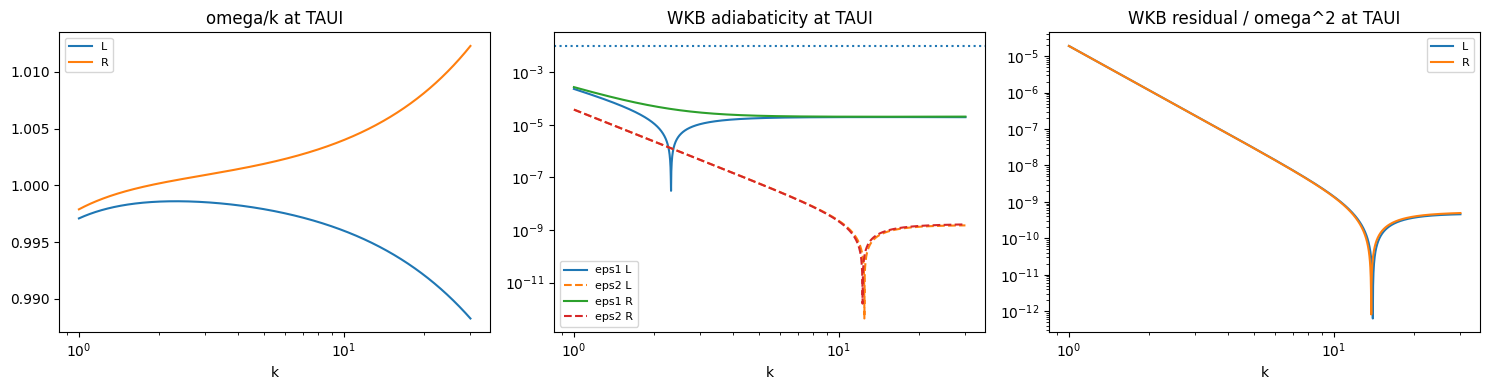

WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
At TAU0: k=  1.000, L, omega^2/k^2=-0.999990, Wronskian=0-1j
At TAU0: k=  1.000, R, omega^2/k^2=-1.000010, Wronskian=0-1j
At TAU0: k=  5.477, L, omega^2/k^2=+0.933123, Wronskian=0-1j
At TAU0: k=  5.477, R, omega^2/k^2=+0.933543, Wronskian=0-1j
At TAU0: k= 30.000, L, omega^2/k^2=+0.996581, Wronskian=0-1j
At TAU0: k= 30.000, R, omega^2/k^2=+0.998978, Wronskian=0-1j


In [2]:
# Check WKB/EFT validity ONLY at TAUI, using main() parameters.
k_array = np.geomspace(K_MIN, K_MAX, N_K)
x_array = -k_array*TAUI
print(f"alpha={ALPHA}, beta={BETA}, H/Lambda={H/LAMBDA:g}")
print(f"TAUI={TAUI:g}; TAU0={TAU0:g}; TAUF={TAUF:g}")
print(f"WKB initial x range = [{x_array.min():g}, {x_array.max():g}]")
print(f"max |c1(TAUI)| = {np.max(np.abs(ALPHA*H/LAMBDA*x_array)):.6g}")
print(f"max |c2(TAUI)| = {np.max(np.abs(BETA*H/LAMBDA*x_array)):.6g}")
print(f"max p(TAUI)/Lambda = {np.max(H/LAMBDA*x_array):.6g}")

fig, axes = plt.subplots(1,3,figsize=(15,4))
for label,sig in (("L",+1),("R",-1)):
    omega,omegap,eps1,eps2,resid = wkb_data_at_tau(TAUI,k_array,sig)
    print(f"{label}: max eps1={np.max(eps1):.6e}, "
          f"max eps2={np.max(eps2):.6e}, max residual={np.max(resid):.6e}")
    axes[0].semilogx(k_array,omega/k_array,label=label)
    axes[1].loglog(k_array,eps1,label=f"eps1 {label}")
    axes[1].loglog(k_array,eps2,ls="--",label=f"eps2 {label}")
    axes[2].loglog(k_array,resid,label=label)
axes[0].set_title("omega/k at TAUI")
axes[1].set_title("WKB adiabaticity at TAUI")
axes[2].set_title("WKB residual / omega^2 at TAUI")
for ax in axes:
    ax.set_xlabel("k")
    ax.legend(fontsize=8)
axes[1].axhline(WKB_EPS_LIMIT,ls=":",label="threshold")
fig.tight_layout()
plt.show()
validate_configuration()

# The transported free mode retains its Wronskian, even though omega^2 may be
# negative for some k at TAU0.  These modes are then used to prepare B(TAU0).
for k0 in (K_MIN, np.sqrt(K_MIN*K_MAX), K_MAX):
    for label,sig in (("L",+1),("R",-1)):
        g,gp = transported_free_mode(k0,sig)
        w = g*np.conjugate(gp)-gp*np.conjugate(g)
        print(f"At TAU0: k={k0:7.3f}, {label}, "
              f"omega^2/k^2={omega_squared_exact(TAU0,k0,sig)/k0**2:+.6f}, "
              f"Wronskian={w:.6g}")


## Baseline: no entanglement


WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=3000

  completed  300/3000 modes
  completed  600/3000 modes
  completed  900/3000 modes
  completed 1200/3000 modes
  completed 1500/3000 modes
  completed 1800/3000 modes
  completed 2100/3000 modes
  completed 2400/3000 modes
  completed 2700/3000 modes
  completed 3000/3000 modes


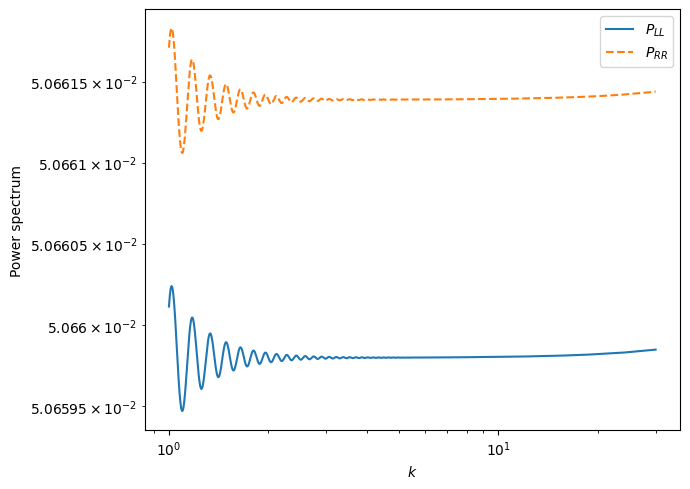


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.24612380e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.81278603e-16

Outputs:
  parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv
  parity_violation_General_outputs/case_00/parity_power_spectrum_LL_RR.png
  parity_violation_General_outputs/case_00/parity_asymmetry_Pi.png
  parity_violation_General_outputs/case_00/parity_cross_power_RL.png
  parity_violation_General_outputs/case_00/parity_normalizability_margin.png


In [3]:
BTILDE1_AMP = 0.0
BTILDE2_AMP = 0.0
OUTPUT_DIR = Path("parity_violation_General_outputs") / "case_00"
results_00 = main()


## Gaussian entanglement: btilde_1 = btilde_3 = 0.30


WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=3000

  completed  300/3000 modes
  completed  600/3000 modes
  completed  900/3000 modes
  completed 1200/3000 modes
  completed 1500/3000 modes
  completed 1800/3000 modes
  completed 2100/3000 modes
  completed 2400/3000 modes
  completed 2700/3000 modes
  completed 3000/3000 modes


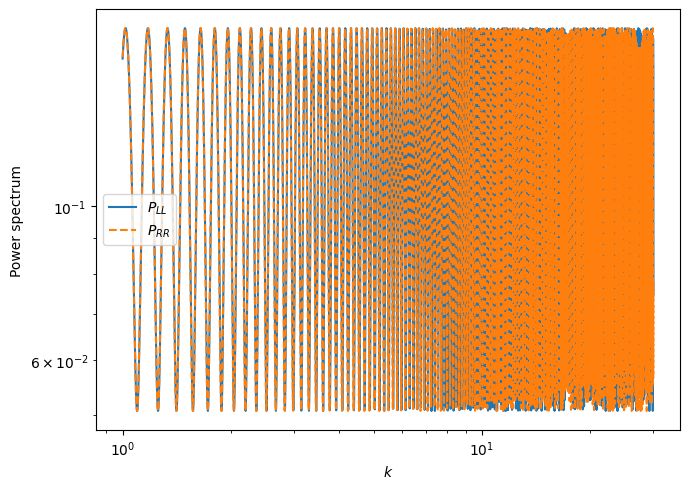


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.88865796e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.22044605e-16

Outputs:
  parity_violation_General_outputs/case_33/parity_violation_power_spectra.csv
  parity_violation_General_outputs/case_33/parity_power_spectrum_LL_RR.png
  parity_violation_General_outputs/case_33/parity_asymmetry_Pi.png
  parity_violation_General_outputs/case_33/parity_cross_power_RL.png
  parity_violation_General_outputs/case_33/parity_normalizability_margin.png


In [4]:
BTILDE1_AMP = 0.30
BTILDE2_AMP = 0.30
OUTPUT_DIR = Path("parity_violation_General_outputs") / "case_33"
results_33 = main()


## Gaussian entanglement: btilde_1 = 0.10, btilde_3 = 0.30


WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=3000

  completed  300/3000 modes
  completed  600/3000 modes
  completed  900/3000 modes
  completed 1200/3000 modes
  completed 1500/3000 modes
  completed 1800/3000 modes
  completed 2100/3000 modes
  completed 2400/3000 modes
  completed 2700/3000 modes
  completed 3000/3000 modes


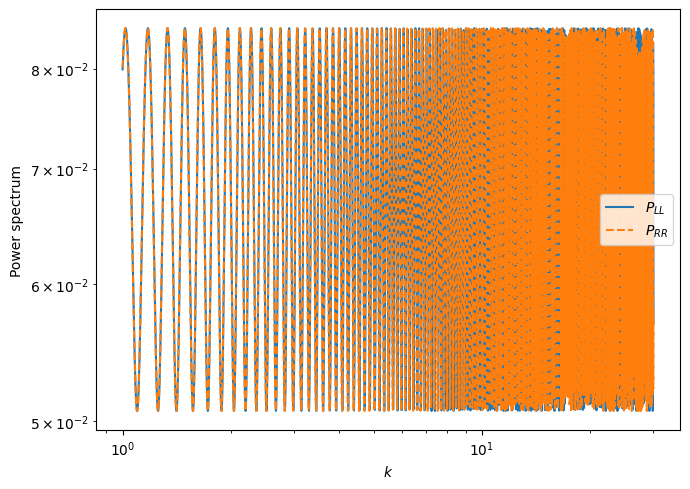


Finished successfully.
minimum normalization margin over sampled (tau,k) = 4.58280320e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.35922393e-16

Outputs:
  parity_violation_General_outputs/case_13/parity_violation_power_spectra.csv
  parity_violation_General_outputs/case_13/parity_power_spectrum_LL_RR.png
  parity_violation_General_outputs/case_13/parity_asymmetry_Pi.png
  parity_violation_General_outputs/case_13/parity_cross_power_RL.png
  parity_violation_General_outputs/case_13/parity_normalizability_margin.png


In [5]:
BTILDE1_AMP = 0.10
BTILDE2_AMP = 0.30
OUTPUT_DIR = Path("parity_violation_General_outputs") / "case_13"
results_13 = main()


## Comparison of parity-asymmetry spectra


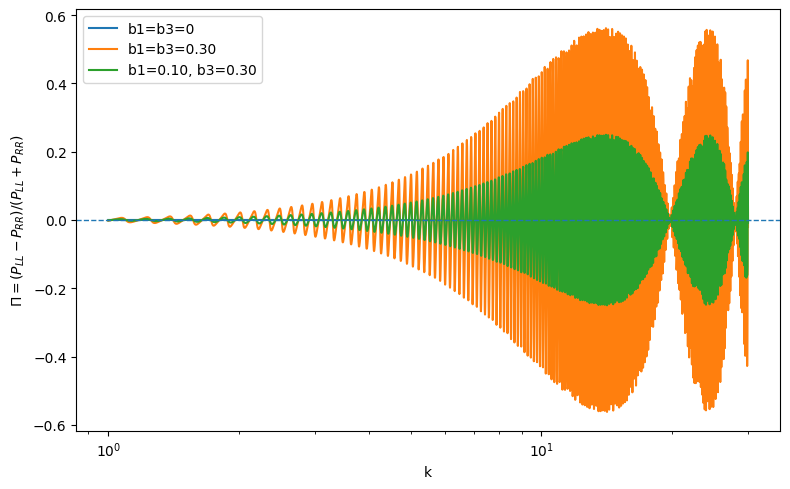

In [6]:
# Plot the parity asymmetry for all computed entanglement cases.
plt.figure(figsize=(8,5))
for result,label in ((results_00,"b1=b3=0"),
                     (results_33,"b1=b3=0.30"),
                     (results_13,"b1=0.10, b3=0.30")):
    plt.semilogx(result["k"], result["Pi"], label=label)
plt.axhline(0,ls="--",lw=1)
plt.xlabel("k")
plt.ylabel(r"$\Pi=(P_{LL}-P_{RR})/(P_{LL}+P_{RR})$")
plt.legend()
plt.tight_layout()
plt.show()


# Optional: WKB-based GR / CS runs saved separately
RUN_MODEL_COMPARISON = True generates GR_from_WKB/case_00,case_33,case_13 and CS_from_WKB/case_00,case_33,case_13. The original CS (HyperU) outputs in parity_violation_CS_BD_outputs and older model outputs are untouched. All WKB model runs use the same TAUI, TAU0, TAUF and k grid; each run's own output folder is created by main(). This computation is relatively expensive; set the flag to False to skip it.


Running GR / case_00 -> GR_from_WKB/case_00
WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0, max |c2|=0
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 0.00000000e+00
beta  = 0.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 3.00000000e+01] with N_K=3000

  completed  300/3000 modes
  completed  600/3000 modes
  completed  900/3000 modes
  completed 1200/3000 modes
  completed 1500/3000 modes
  completed 1800/3000 modes
  completed 2100/3000 modes
  completed 2400/3000 modes
  completed 2700/3000 modes
  completed 3000/3000 modes


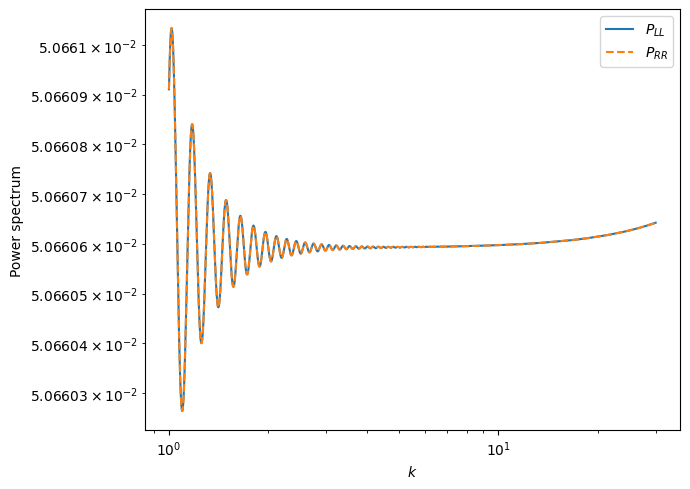


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.24687108e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 1.00000000e+00
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 0.00000000e+00

Outputs:
  GR_from_WKB/case_00/parity_violation_power_spectra.csv
  GR_from_WKB/case_00/parity_power_spectrum_LL_RR.png
  GR_from_WKB/case_00/parity_asymmetry_Pi.png
  GR_from_WKB/case_00/parity_cross_power_RL.png
  GR_from_WKB/case_00/parity_normalizability_margin.png

Running GR / case_33 -> GR_from_WKB/case_33
WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0, max |c2|=0
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 0.00000000e+00
beta  = 0.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.0000

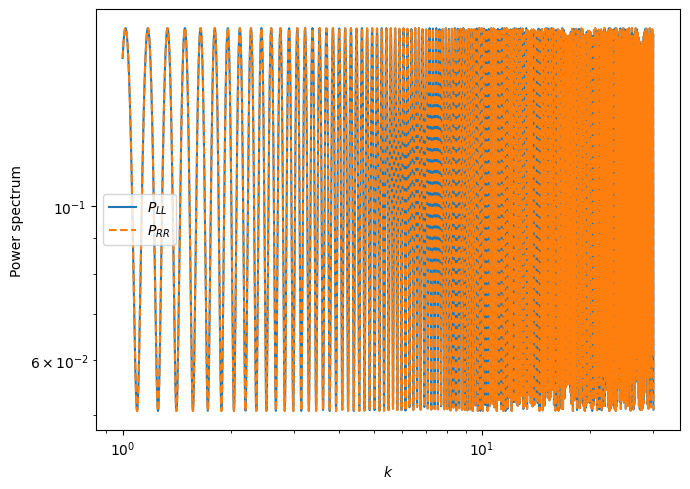


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.88865885e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 1.00000000e+00
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 0.00000000e+00

Outputs:
  GR_from_WKB/case_33/parity_violation_power_spectra.csv
  GR_from_WKB/case_33/parity_power_spectrum_LL_RR.png
  GR_from_WKB/case_33/parity_asymmetry_Pi.png
  GR_from_WKB/case_33/parity_cross_power_RL.png
  GR_from_WKB/case_33/parity_normalizability_margin.png

Running GR / case_13 -> GR_from_WKB/case_13
WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0, max |c2|=0
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 0.00000000e+00
beta  = 0.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.0000

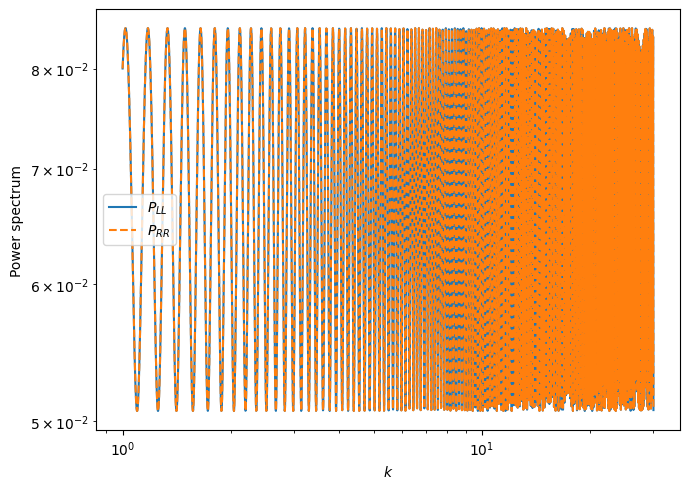


Finished successfully.
minimum normalization margin over sampled (tau,k) = 4.58280569e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 1.00000000e+00
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 0.00000000e+00

Outputs:
  GR_from_WKB/case_13/parity_violation_power_spectra.csv
  GR_from_WKB/case_13/parity_power_spectrum_LL_RR.png
  GR_from_WKB/case_13/parity_asymmetry_Pi.png
  GR_from_WKB/case_13/parity_cross_power_RL.png
  GR_from_WKB/case_13/parity_normalizability_margin.png

Running CS / case_00 -> CS_from_WKB/case_00
WKB validity at TAUI=-20.0: min x=20, max x=600
  max |c1|=0.03, max |c2|=0.03
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [

In [ ]:
# Run only when you need to (re)generate the 6 WKB model datasets.
# Set True, execute this cell, then execute the Pi-comparison cell below.
RUN_MODEL_COMPARISON = True

if RUN_MODEL_COMPARISON:
    original_config = (
        ALPHA, BETA, BTILDE1_AMP, BTILDE2_AMP, INITIAL_MODE, OUTPUT_DIR
    )
    wkb_results = {}
    model_settings = [
        ("GR", 0.0, 0.0, Path("GR_from_WKB")),
        ("CS", 5.0, 5.0, Path("CS_from_WKB")),
    ]
    case_settings = [
        ("00", 0.0, 0.0),
        ("33", 0.30, 0.30),
        ("13", 0.10, 0.30),
    ]
    try:
        INITIAL_MODE = "wkb_transport"
        for model_name, alpha, beta, root in model_settings:
            ALPHA, BETA = alpha, beta
            for case, b1_amp, b2_amp in case_settings:
                BTILDE1_AMP, BTILDE2_AMP = b1_amp, b2_amp
                OUTPUT_DIR = root / f"case_{case}"
                print(f"\nRunning {model_name} / case_{case} -> {OUTPUT_DIR}")
                wkb_results[(model_name, case)] = main()
    finally:
        (ALPHA, BETA, BTILDE1_AMP, BTILDE2_AMP,
         INITIAL_MODE, OUTPUT_DIR) = original_config

    # Optional diagnostic: additional Pi from entanglement, within each model.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    for ax, model_name in zip(axes, ("GR", "CS")):
        baseline = wkb_results[(model_name, "00")]
        for case, b1_amp, b2_amp in case_settings[1:]:
            ent = wkb_results[(model_name, case)]
            ax.semilogx(
                ent["k"], ent["Pi"] - baseline["Pi"],
                label=rf"$\tilde b_1={b1_amp:g},\;\tilde b_2={b2_amp:g}$"
            )
        ax.axhline(0, color="gray", linestyle=":")
        ax.set_title(f"{model_name} (WKB): entanglement-induced $\Delta\Pi$")
        ax.set_xlabel(r"$k$")
        ax.set_ylabel(r"$\Pi_{\mathrm{ent}}-\Pi_{00}$")
        ax.legend(fontsize=9)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    comparison_output = Path("Pi_comparison_WKB_vs_HyperU")
    comparison_output.mkdir(parents=True, exist_ok=True)
    fig.savefig(comparison_output / "Pi_entanglement_effect_WKB.png", dpi=220)
    plt.show()


In [ ]:
from pathlib import Path

print("現在の作業ディレクトリ:", Path.cwd())

for case in ("00", "13", "33"):
    path = (
        Path("CS_from_WKB")
        / f"case_{case}"
        / "parity_violation_power_spectra.csv"
    )
    print(case, path.resolve(), path.exists())

現在の作業ディレクトリ: /Users/ueda/Desktop/GWsEntanglement
00 /Users/ueda/Desktop/GWsEntanglement/CS_from_WKB/case_00/parity_violation_power_spectra.csv True
13 /Users/ueda/Desktop/GWsEntanglement/CS_from_WKB/case_13/parity_violation_power_spectra.csv True
33 /Users/ueda/Desktop/GWsEntanglement/CS_from_WKB/case_33/parity_violation_power_spectra.csv True


# WKB comparisons: $\Delta\Pi$ (case 33), and $\Pi_{\rm CS}/\Pi_{\rm General}$ (all cases)
We define $\Delta\Pi=\Pi_{\rm ent}-\Pi_{00}$ within each gravity model. Comparisons use WKB at the common state-preparation time $\tau_i$. In the ratio plot, a nearly-zero denominator is masked; a ratio of 5 is a numerical prediction for the unentangled baseline in this parameter regime, not a general identity. Existing parity_violation_General_outputs CSV files are supported as a fallback.

CS data: /Users/ueda/Desktop/GWsEntanglement/CS_from_WKB
General PV data: /Users/ueda/Desktop/GWsEntanglement/parity_violation_General_outputs


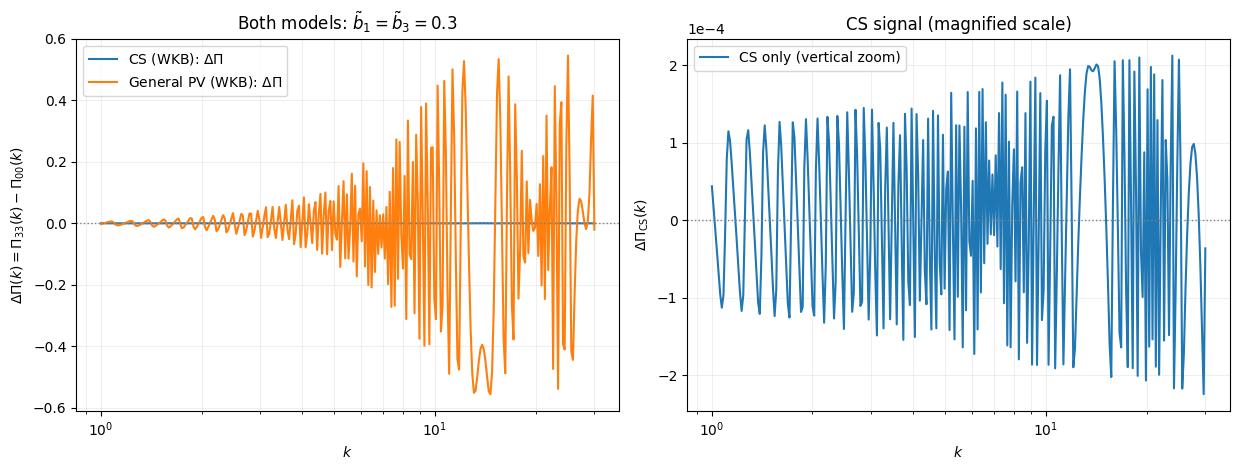

case_00: valid=300/300, median=+5, range=[+4.98148, +5.02162]
case_13: valid=300/300, median=+9.25675e-06, range=[-10.2496, +0.502876]
case_33: valid=300/300, median=-0.000739825, range=[-1.06426, +0.184198]


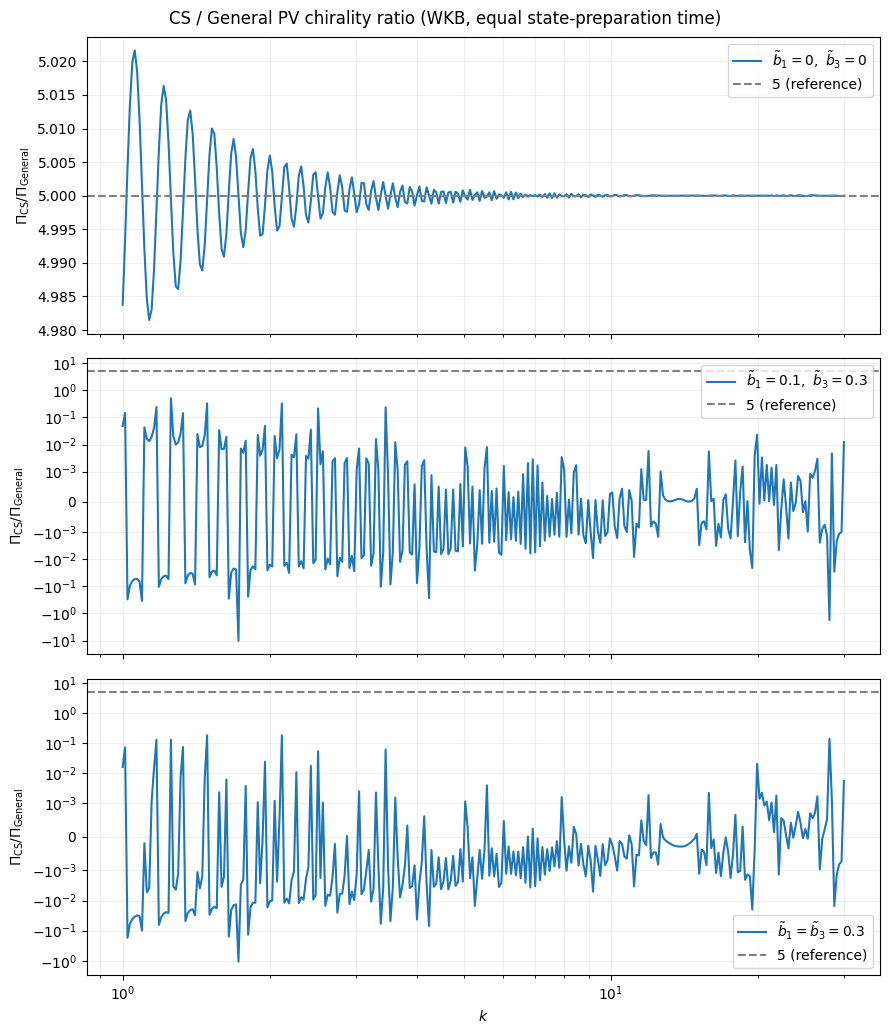

Saved figures: /Users/ueda/Desktop/GWsEntanglement/WKB_Comparisons/DeltaPi_CS_vs_General_case_33.png and /Users/ueda/Desktop/GWsEntanglement/WKB_Comparisons/Pi_ratio_CS_over_General_all_cases.png


{'k33': array([ 1.        ,  1.01144019,  1.02301125,  1.03471469,  1.04655202,
         1.05852477,  1.07063449,  1.08288275,  1.09527113,  1.10780123,
         1.12047468,  1.13329312,  1.14625821,  1.15937161,  1.17263504,
         1.18605021,  1.19961884,  1.2133427 ,  1.22722357,  1.24126324,
         1.25546352,  1.26982625,  1.2843533 ,  1.29904654,  1.31390788,
         1.32893923,  1.34414254,  1.35951978,  1.37507294,  1.39080403,
         1.40671509,  1.42280817,  1.43908536,  1.45554877,  1.47220052,
         1.48904276,  1.50607769,  1.5233075 ,  1.54073442,  1.55836071,
         1.57618865,  1.59422054,  1.61245872,  1.63090554,  1.64956341,
         1.66843472,  1.68752192,  1.70682749,  1.72635391,  1.74610372,
         1.76607947,  1.78628375,  1.80671917,  1.82738838,  1.84829404,
         1.86943887,  1.89082559,  1.91245699,  1.93433586,  1.95646502,
         1.97884734,  2.00148572,  2.02438309,  2.04754241,  2.07096668,
         2.09465892,  2.11862221,  2.1428596

In [ ]:
"""Compare WKB CS and General-PV parity asymmetries using saved CSV outputs.

Usage: run from the notebook's working directory (the folder containing
CS_from_WKB and GeneralPV_from_WKB/parity_violation_General_outputs).
"""
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

CASE_LABELS = {
    "00": r"$\tilde b_1=0,\ \tilde b_3=0$",
    "13": r"$\tilde b_1=0.1,\ \tilde b_3=0.3$",
    "33": r"$\tilde b_1=\tilde b_3=0.3$",
}
CSV_NAME = "parity_violation_power_spectra.csv"
CS_ROOT = Path("CS_from_WKB")
GENERAL_CANDIDATES = (
    Path("GeneralPV_from_WKB"),
    Path("parity_violation_General_outputs"),
)
OUTPUT_ROOT = Path("WKB_Comparisons")


def all_files_exist(root):
    return all((root / f"case_{case}" / CSV_NAME).is_file()
               for case in CASE_LABELS)


def select_general_root():
    for root in GENERAL_CANDIDATES:
        if all_files_exist(root):
            return root
    tried = "\n".join(str(root.resolve()) for root in GENERAL_CANDIDATES)
    raise FileNotFoundError(
        "General PV の全ケースのCSVが見つかりません。既存の case_00, "
        "case_13, case_33 があるか確認してください。\n" + tried
    )


def read_spectrum(root, case):
    path = root / f"case_{case}" / CSV_NAME
    if not path.is_file():
        raise FileNotFoundError(
            f"{path.resolve()}\n先に各WKB計算セルを実行してください。"
        )
    data = np.genfromtxt(path, delimiter=",", names=True)
    required = {"k", "Pi_LL_minus_RR"}
    missing = required.difference(data.dtype.names or ())
    if missing:
        raise ValueError(f"{path}: 必要なCSV列がありません: {sorted(missing)}")
    k = np.atleast_1d(np.asarray(data["k"], dtype=float))
    pi = np.atleast_1d(np.asarray(data["Pi_LL_minus_RR"], dtype=float))
    if len(k) < 2 or not np.all(np.diff(k) > 0):
        raise ValueError(f"{path}: k は昇順で2点以上必要です。")
    if not np.all(np.isfinite(k)) or not np.all(np.isfinite(pi)):
        raise ValueError(f"{path}: 非有限値が含まれています。")
    return k, pi


def pi_on_k_grid(k_ref, k_source, pi_source):
    if k_ref.size == k_source.size and np.allclose(
        k_ref, k_source, rtol=1e-11, atol=1e-12
    ):
        return pi_source
    # Do not extrapolate beyond the source's wavenumber range.
    tolerance = 1e-12 * max(k_ref[-1], k_source[-1], 1.)
    if (k_ref[0] < k_source[0] - tolerance or
            k_ref[-1] > k_source[-1] + tolerance):
        raise ValueError("異なるk範囲です。比較対象のk領域を揃えてください。")
    return np.interp(np.clip(k_ref, k_source[0], k_source[-1]),
                     k_source, pi_source)


def compare(output_root=OUTPUT_ROOT):
    general_root = select_general_root()
    if not all_files_exist(CS_ROOT):
        raise FileNotFoundError(
            f"{CS_ROOT.resolve()} に3ケース分のCSVがありません。"
            " WKBのOptionalセルを実行してください。"
        )
    print("CS data:", CS_ROOT.resolve())
    print("General PV data:", general_root.resolve())
    output_root.mkdir(parents=True, exist_ok=True)

    curves = {}
    for model, root in (("CS", CS_ROOT), ("General", general_root)):
        for case in CASE_LABELS:
            curves[(model, case)] = read_spectrum(root, case)

    # Use the General-PV grid for each comparison; interpolate only if needed.
    aligned = {}
    for case in CASE_LABELS:
        k, pi_general = curves[("General", case)]
        kc, pi_cs = curves[("CS", case)]
        aligned[case] = (k, pi_on_k_grid(k, kc, pi_cs), pi_general)

    # Figure 1: entanglement-induced change, not the raw Pi.
    k, cs_33, general_33 = aligned["33"]
    k_33 = k.copy()
    k0, cs_00, general_00 = aligned["00"]
    baseline_cs = pi_on_k_grid(k, k0, cs_00)
    baseline_general = pi_on_k_grid(k, k0, general_00)
    delta_cs = cs_33 - baseline_cs
    delta_general = general_33 - baseline_general
    fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(12.5, 4.8), sharex=True)
    ax.semilogx(k, delta_cs, label=r"CS (WKB): $\Delta\Pi$")
    ax.semilogx(k, delta_general, label=r"General PV (WKB): $\Delta\Pi$")
    ax.axhline(0, color="gray", ls=":", lw=1)
    ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)=\Pi_{33}(k)-\Pi_{00}(k)$",
           title=r"Both models: $\tilde b_1=\tilde b_3=0.3$")
    ax.grid(True, which="both", alpha=0.2)
    ax.legend()
    # The CS signal is much smaller: provide a readable zoom as well.
    ax_zoom.semilogx(k, delta_cs, label="CS only (vertical zoom)")
    ax_zoom.axhline(0, color="gray", ls=":", lw=1)
    ax_zoom.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi_{\rm CS}(k)$",
                title="CS signal (magnified scale)")
    ax_zoom.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax_zoom.grid(True, which="both", alpha=0.2)
    ax_zoom.legend()
    fig.tight_layout()
    saved_delta = output_root / "DeltaPi_CS_vs_General_case_33.png"
    fig.savefig(saved_delta, dpi=220)
    plt.show()
    plt.close(fig)

    # Figure 2: direct CS / General-PV chirality ratio, all cases.
    fig, axes = plt.subplots(3, 1, figsize=(9, 10.5), sharex=True)
    for ax, (case, label) in zip(axes, CASE_LABELS.items()):
        k, pi_cs, pi_general = aligned[case]
        # Mask nearly-zero denominators instead of plotting artificial infinities.
        eps = max(1e-12, 1e-7*np.max(np.abs(pi_general)))
        ratio = np.full(pi_general.shape, np.nan, dtype=float)
        ok = np.abs(pi_general) > eps
        np.divide(pi_cs, pi_general, out=ratio, where=ok)
        ax.semilogx(k, ratio, label=label)
        ax.axhline(5.0, color="gray", ls="--", label="5 (reference)")
        if case != "00":
            # Highlight both signs and small nonzero ratios without clipping outliers.
            ax.set_yscale("symlog", linthresh=1e-3)
        ax.set_ylabel(r"$\Pi_{\rm CS}/\Pi_{\rm General}$")
        ax.grid(True, which="both", alpha=0.2)
        ax.legend(loc="best")
        finite = ratio[np.isfinite(ratio)]
        if finite.size:
            print(f"case_{case}: valid={finite.size}/{ratio.size}, "
                  f"median={np.median(finite):+.6g}, "
                  f"range=[{np.min(finite):+.6g}, {np.max(finite):+.6g}]")
    axes[-1].set_xlabel(r"$k$")
    fig.suptitle("CS / General PV chirality ratio (WKB, equal state-preparation time)")
    fig.tight_layout()
    saved_ratio = output_root / "Pi_ratio_CS_over_General_all_cases.png"
    fig.savefig(saved_ratio, dpi=220)
    plt.show()
    plt.close(fig)
    print("Saved figures:", saved_delta.resolve(), "and", saved_ratio.resolve())
    return {"k33": k_33, "delta_cs": delta_cs,
            "delta_general": delta_general, "saved_delta": saved_delta,
            "saved_ratio": saved_ratio}


compare()


WKB validity at TAUI=-20.0: min x=240, max x=360
  max |c1|=0.018, max |c2|=0.0036
  max p/Lambda=0.0036
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.20000000e+01, 1.80000000e+01] with N_K=800

  completed   80/800 modes
  completed  160/800 modes
  completed  240/800 modes
  completed  320/800 modes
  completed  400/800 modes
  completed  480/800 modes
  completed  560/800 modes
  completed  640/800 modes
  completed  720/800 modes
  completed  800/800 modes


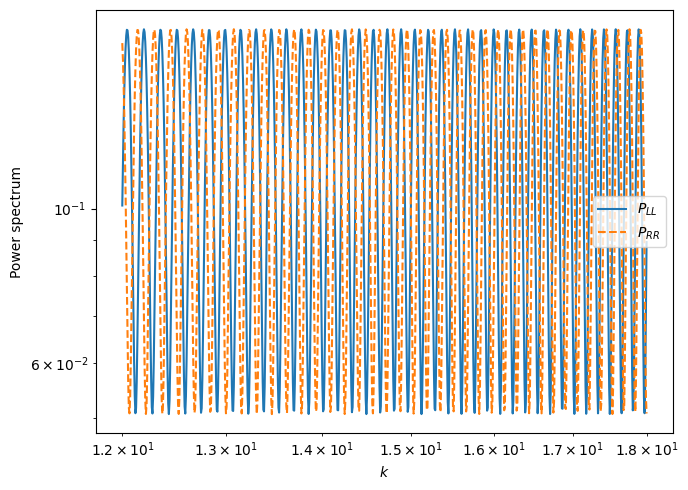


Finished successfully.
minimum normalization margin over sampled (tau,k) = 2.27188402e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.82000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.22044605e-16

Outputs:
  WKB_zoom_12_18/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_12_18/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_12_18/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_12_18/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_12_18/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=240, max x=360
  max |c1|=0.018, max |c2|=0.018
  max p/Lambda=0.0036
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.

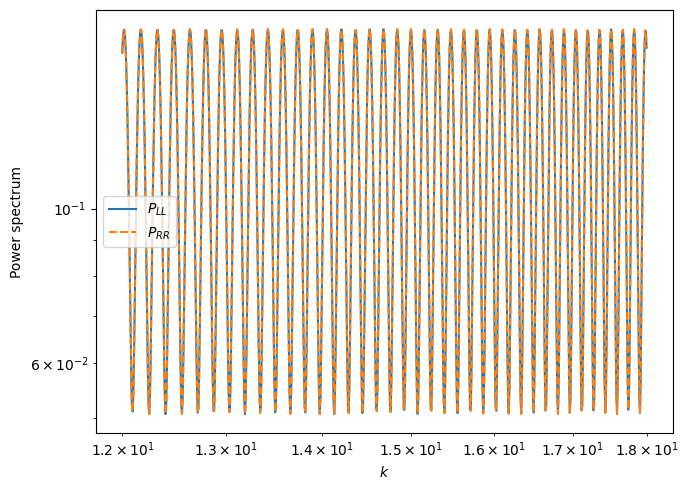


Finished successfully.
minimum normalization margin over sampled (tau,k) = 2.27168212e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.82000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.94804025e-16

Outputs:
  WKB_zoom_12_18/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_12_18/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_12_18/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_12_18/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_12_18/CS/case_33/parity_normalizability_margin.png


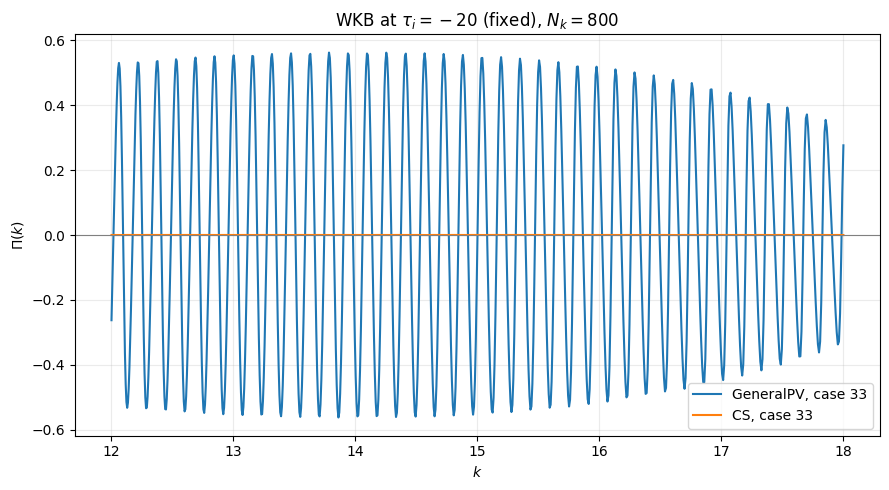

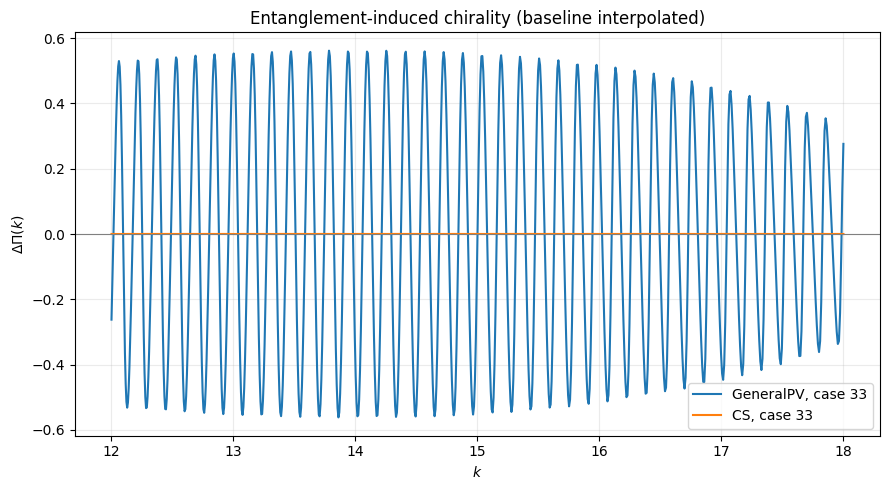

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_12_18


In [ ]:
RUN_ZOOM_K15 = False  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 12.0, 18.0, 800
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_12_18")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=240, max x=260
  max |c1|=0.013, max |c2|=0.0026
  max p/Lambda=0.0026
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.20000000e+01, 1.30000000e+01] with N_K=800

  completed   80/800 modes
  completed  160/800 modes
  completed  240/800 modes
  completed  320/800 modes
  completed  400/800 modes
  completed  480/800 modes
  completed  560/800 modes
  completed  640/800 modes
  completed  720/800 modes
  completed  800/800 modes


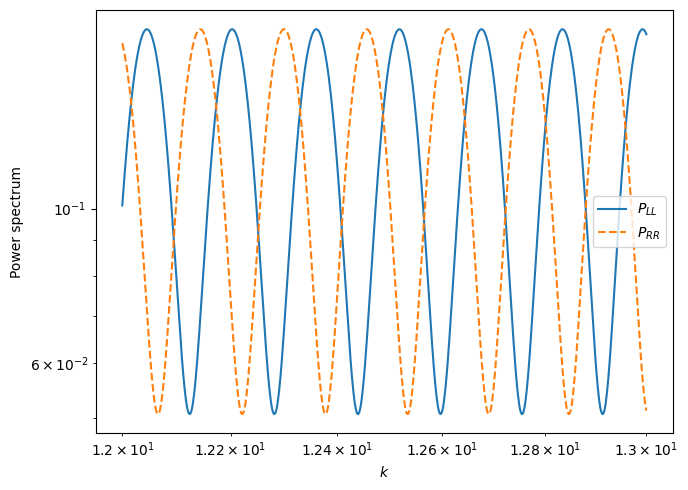


Finished successfully.
minimum normalization margin over sampled (tau,k) = 2.27188402e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.87000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.94289029e-16

Outputs:
  WKB_zoom_12_13/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_12_13/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_12_13/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_12_13/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_12_13/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=240, max x=260
  max |c1|=0.013, max |c2|=0.013
  max p/Lambda=0.0026
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.

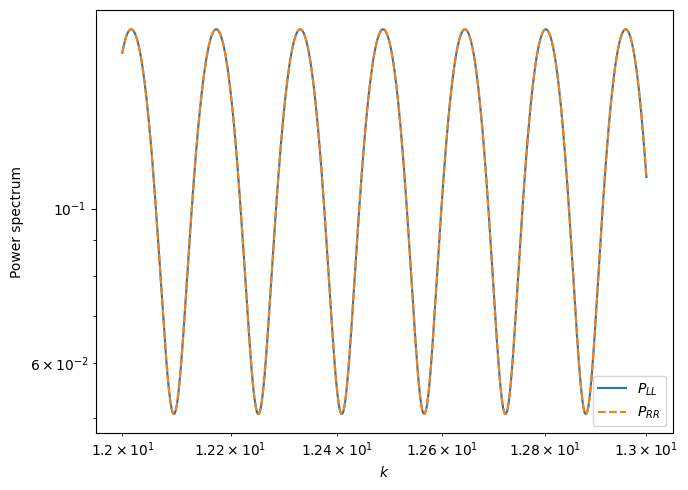


Finished successfully.
minimum normalization margin over sampled (tau,k) = 2.27168212e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.87000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.29471390e-16

Outputs:
  WKB_zoom_12_13/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_12_13/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_12_13/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_12_13/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_12_13/CS/case_33/parity_normalizability_margin.png


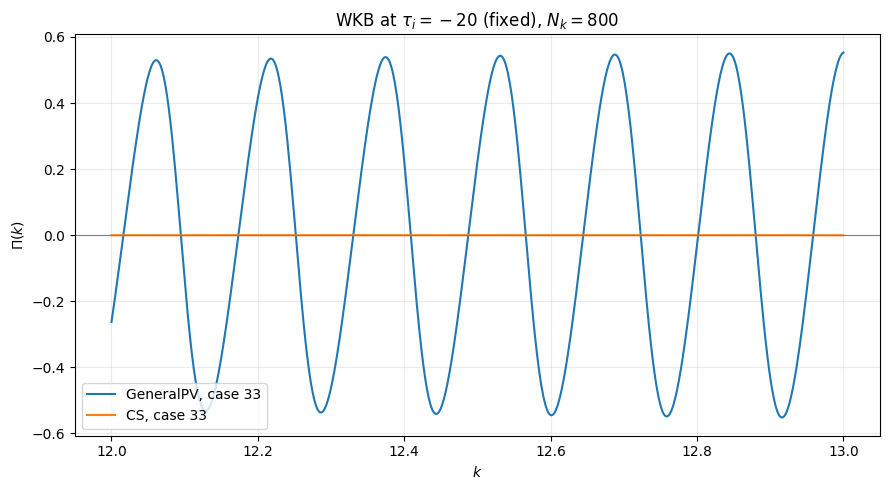

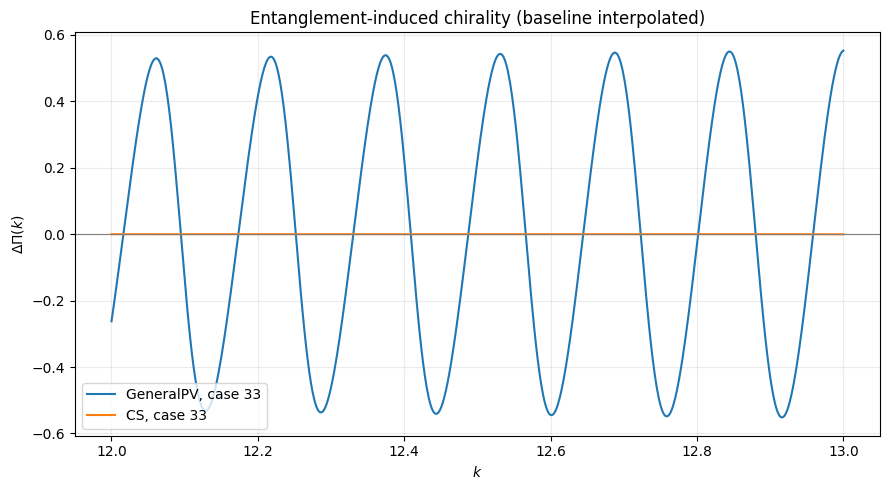

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_12_13


In [ ]:
RUN_ZOOM_K15 = False  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 12.0, 13.0, 800
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_12_13")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=20, max x=100
  max |c1|=0.005, max |c2|=0.001
  max p/Lambda=0.001
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.00000000e+00, 5.00000000e+00] with N_K=800

  completed   80/800 modes
  completed  160/800 modes
  completed  240/800 modes
  completed  320/800 modes
  completed  400/800 modes
  completed  480/800 modes
  completed  560/800 modes
  completed  640/800 modes
  completed  720/800 modes
  completed  800/800 modes


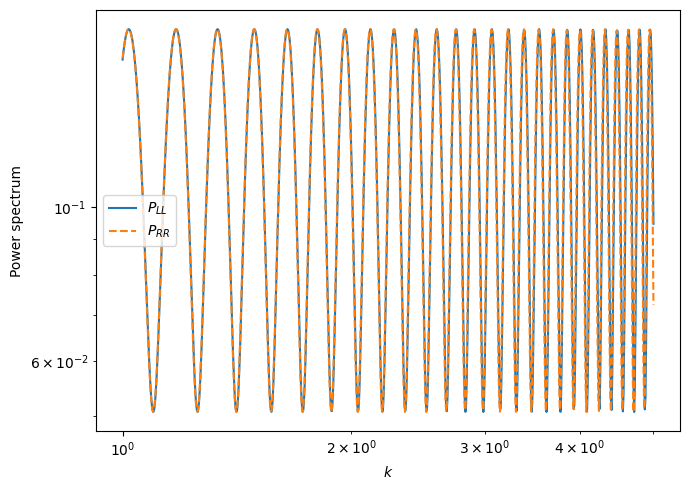


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.88865796e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.95000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.90819582e-16

Outputs:
  WKB_zoom_1_5/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_1_5/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_1_5/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_1_5/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_1_5/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=20, max x=100
  max |c1|=0.005, max |c2|=0.005
  max p/Lambda=0.001
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05

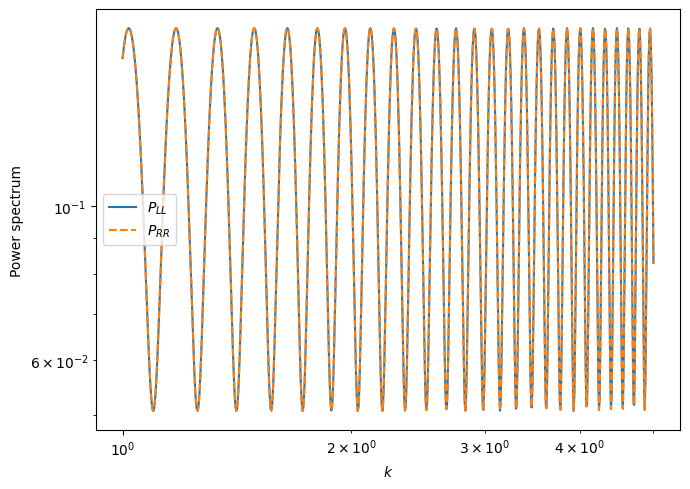


Finished successfully.
minimum normalization margin over sampled (tau,k) = 1.88865679e-04
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.95000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.09671148e-16

Outputs:
  WKB_zoom_1_5/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_1_5/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_1_5/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_1_5/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_1_5/CS/case_33/parity_normalizability_margin.png


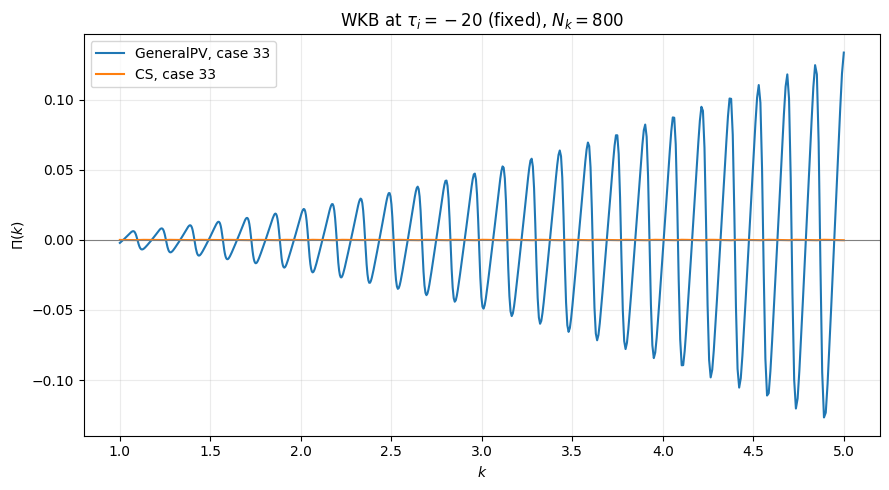

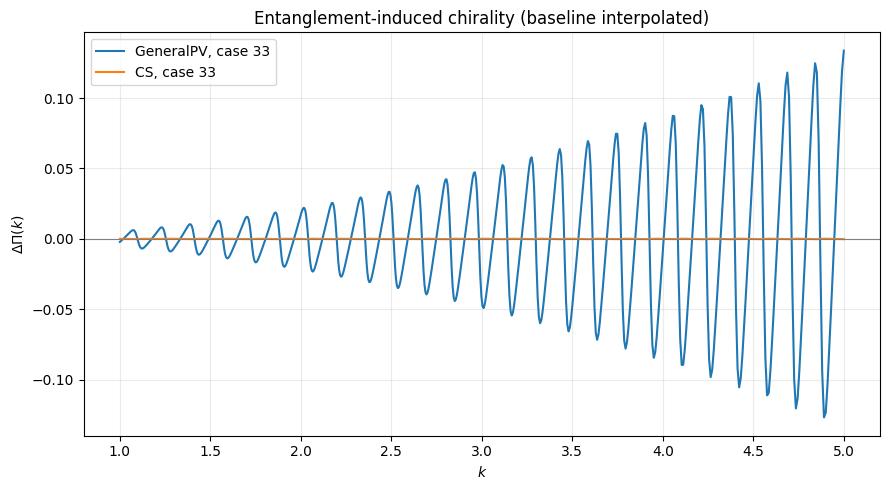

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_1_5


In [ ]:
RUN_ZOOM_K15 = False  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 1.0, 5.0, 800
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_1_5")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=360, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.80000000e+01, 3.00000000e+01] with N_K=1000

  completed  100/1000 modes
  completed  200/1000 modes
  completed  300/1000 modes
  completed  400/1000 modes
  completed  500/1000 modes
  completed  600/1000 modes
  completed  700/1000 modes
  completed  800/1000 modes
  completed  900/1000 modes
  completed 1000/1000 modes


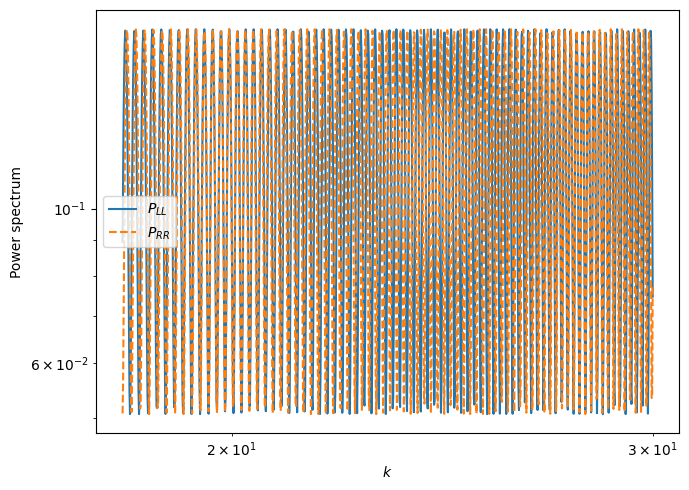


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.40756924e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.22044605e-16

Outputs:
  WKB_zoom_18_30/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_18_30/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_18_30/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_18_30/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_18_30/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=360, max x=600
  max |c1|=0.03, max |c2|=0.03
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.333

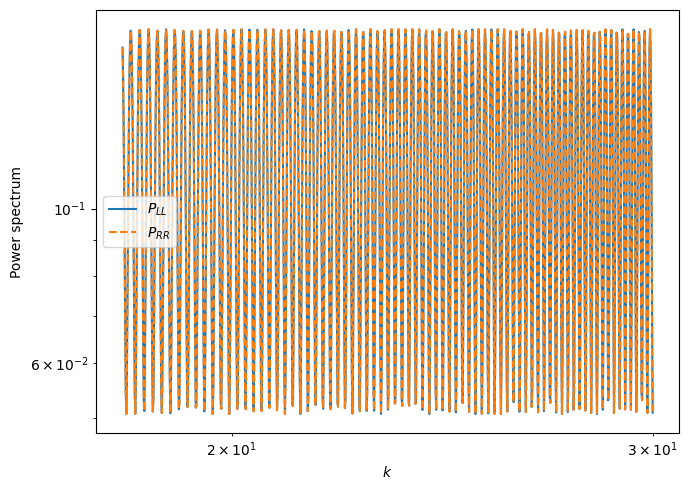


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.40688786e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.86103303e-16

Outputs:
  WKB_zoom_18_30/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_18_30/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_18_30/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_18_30/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_18_30/CS/case_33/parity_normalizability_margin.png


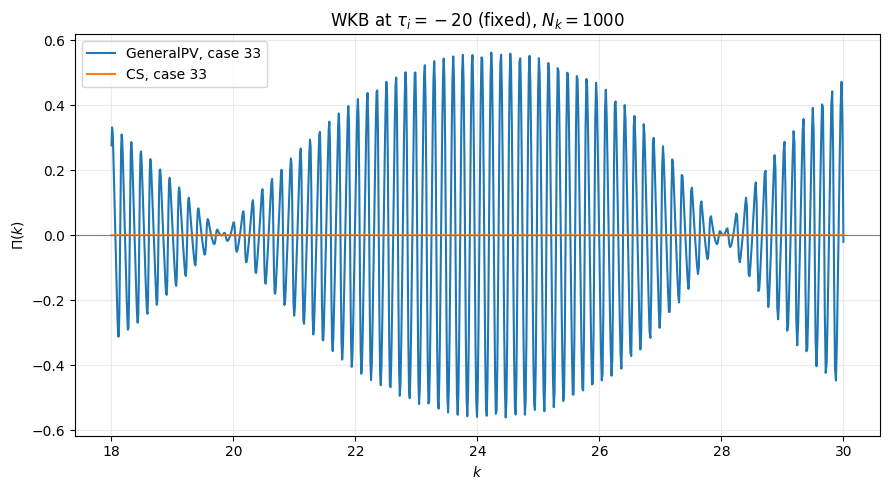

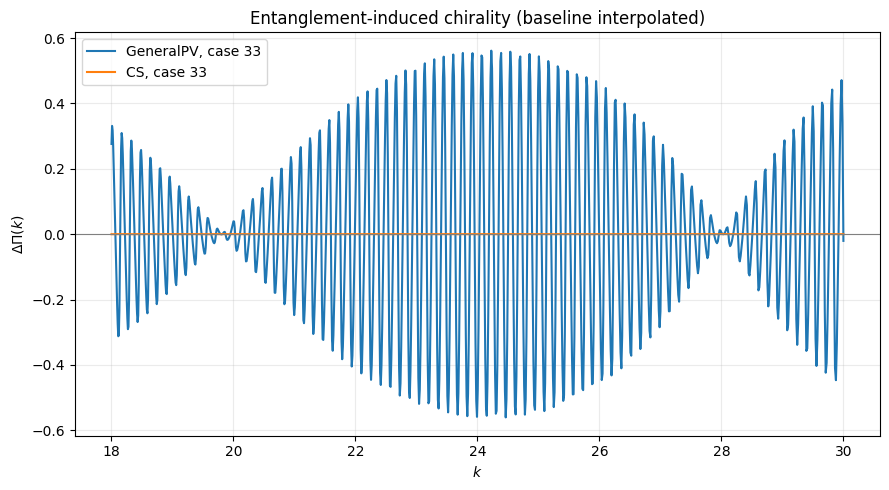

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_18_30


In [ ]:
RUN_ZOOM_K15 = False  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 18.0, 30.0, 1000
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_18_30")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=580, max x=600
  max |c1|=0.03, max |c2|=0.006
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [2.90000000e+01, 3.00000000e+01] with N_K=800

  completed   80/800 modes
  completed  160/800 modes
  completed  240/800 modes
  completed  320/800 modes
  completed  400/800 modes
  completed  480/800 modes
  completed  560/800 modes
  completed  640/800 modes
  completed  720/800 modes
  completed  800/800 modes


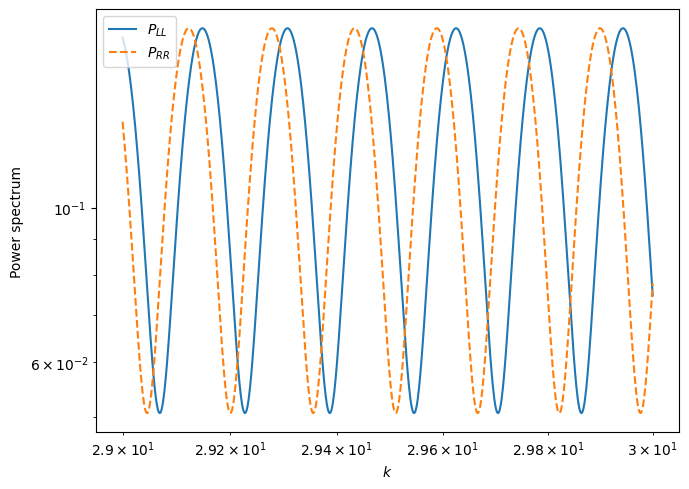


Finished successfully.
minimum normalization margin over sampled (tau,k) = 5.48865806e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.22044605e-16

Outputs:
  WKB_zoom_29_30/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_29_30/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_29_30/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_29_30/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_29_30/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=580, max x=600
  max |c1|=0.03, max |c2|=0.03
  max p/Lambda=0.006
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.333

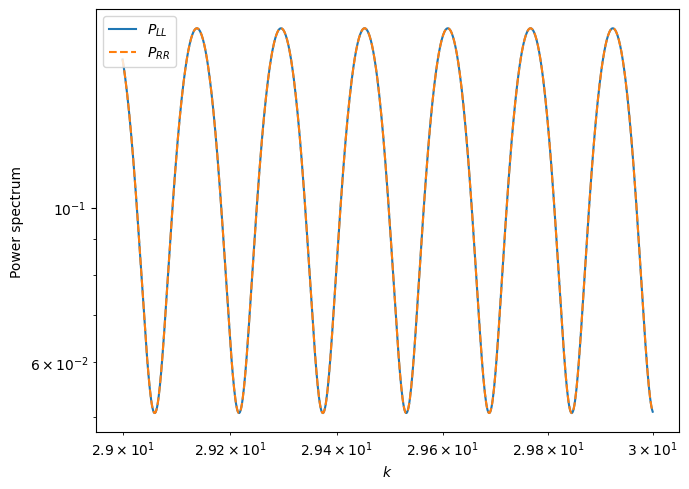


Finished successfully.
minimum normalization margin over sampled (tau,k) = 5.48580913e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.70000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.99574515e-16

Outputs:
  WKB_zoom_29_30/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_29_30/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_29_30/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_29_30/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_29_30/CS/case_33/parity_normalizability_margin.png


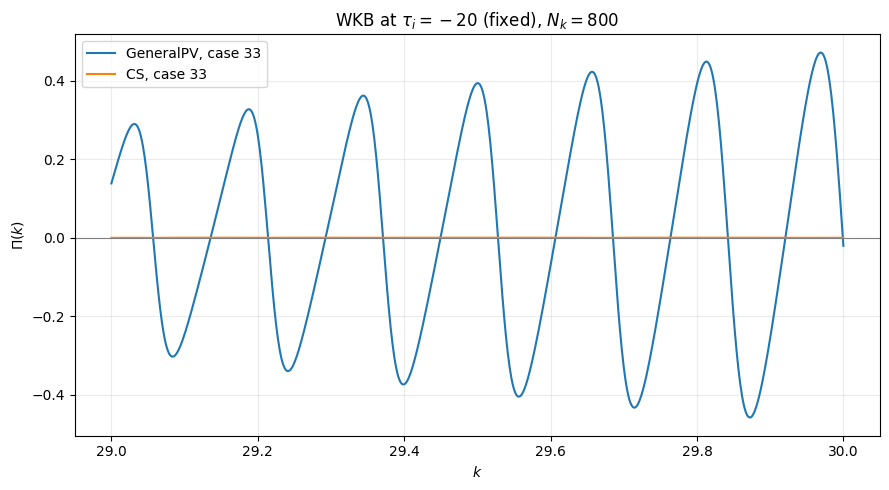

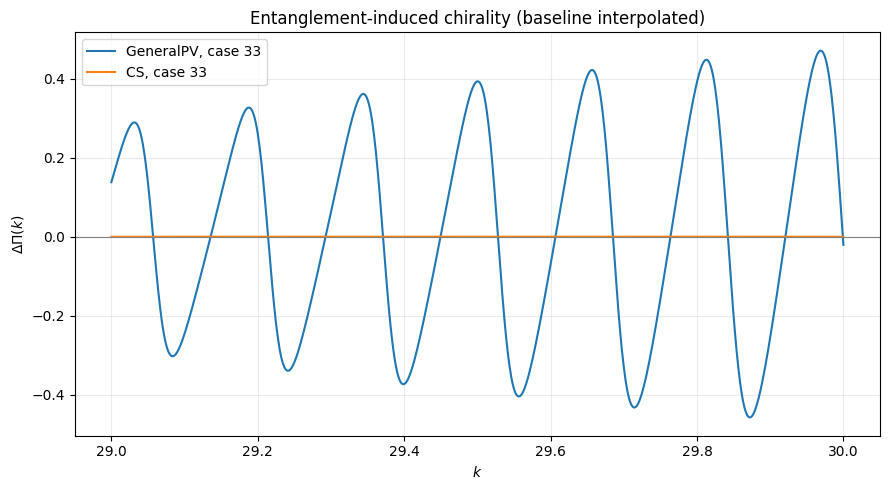

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_29_30


In [ ]:
RUN_ZOOM_K15 = False  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 29.0, 30.0, 800
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_29_30")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=400, max x=420
  max |c1|=0.021, max |c2|=0.0042
  max p/Lambda=0.0042
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [2.00000000e+01, 2.10000000e+01] with N_K=800

  completed   80/800 modes
  completed  160/800 modes
  completed  240/800 modes
  completed  320/800 modes
  completed  400/800 modes
  completed  480/800 modes
  completed  560/800 modes
  completed  640/800 modes
  completed  720/800 modes
  completed  800/800 modes


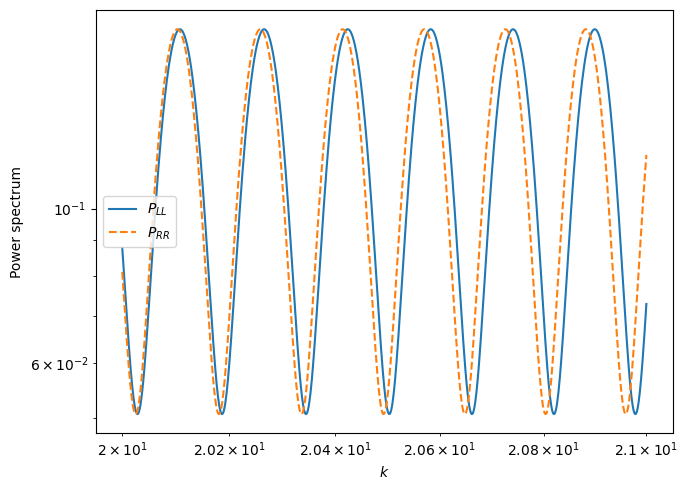


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.78605769e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.79000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.94289029e-16

Outputs:
  WKB_zoom_20_21/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_20_21/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_20_21/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_20_21/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_20_21/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=400, max x=420
  max |c1|=0.021, max |c2|=0.021
  max p/Lambda=0.0042
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.

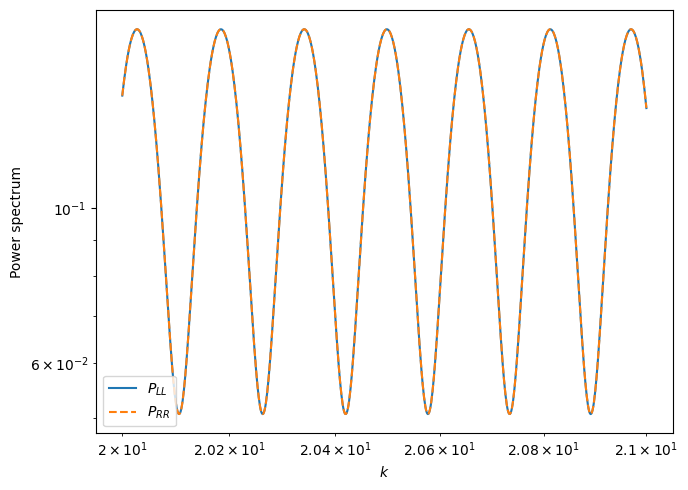


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.78512305e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.79000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.11636264e-16

Outputs:
  WKB_zoom_20_21/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_20_21/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_20_21/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_20_21/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_20_21/CS/case_33/parity_normalizability_margin.png


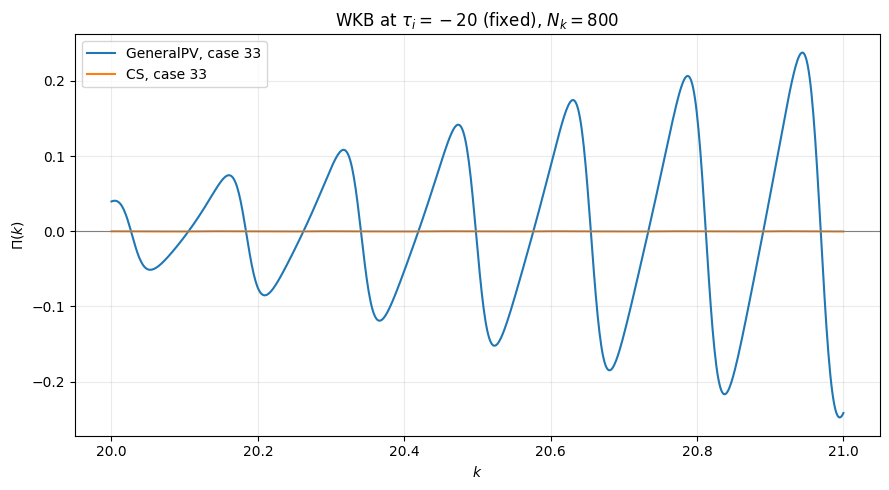

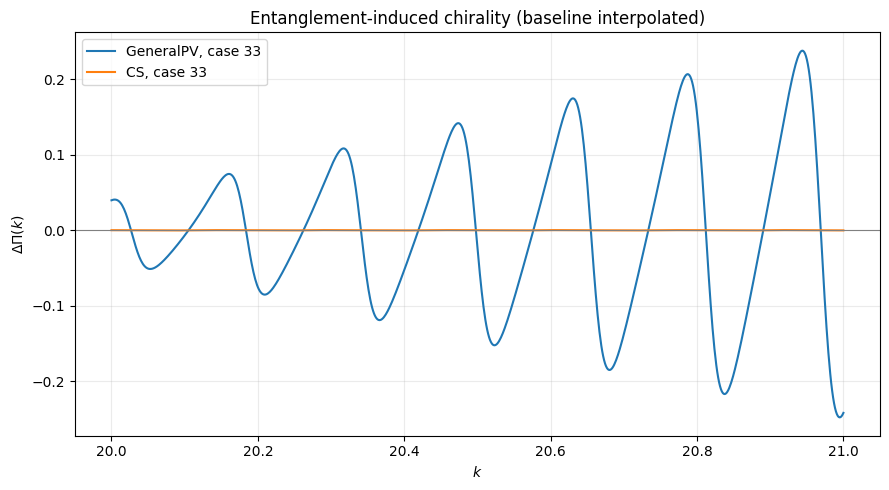

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_20_21


In [ ]:
RUN_ZOOM_K15 = True  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 20.0, 21.0, 800
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_20_21")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")

WKB validity at TAUI=-20.0: min x=360, max x=400
  max |c1|=0.02, max |c2|=0.004
  max p/Lambda=0.004
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 1.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.33333333e-05
k range = [1.80000000e+01, 2.00000000e+01] with N_K=1600

  completed  160/1600 modes
  completed  320/1600 modes
  completed  480/1600 modes
  completed  640/1600 modes
  completed  800/1600 modes
  completed  960/1600 modes
  completed 1120/1600 modes
  completed 1280/1600 modes
  completed 1440/1600 modes
  completed 1600/1600 modes


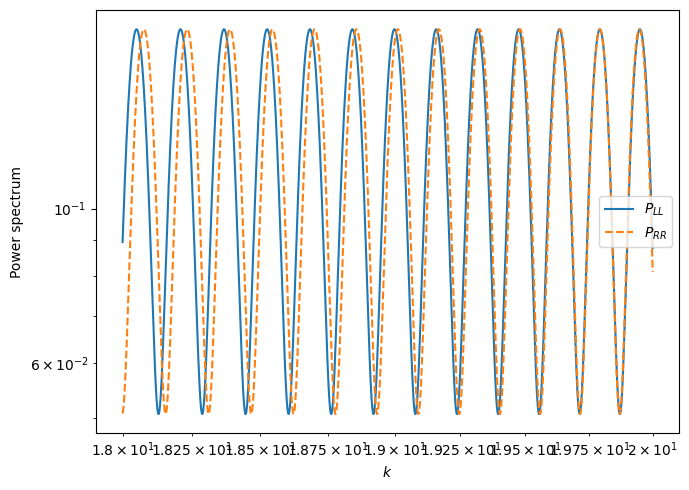


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.40756924e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.80000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 1.80411242e-16

Outputs:
  WKB_zoom_18_20/GeneralPV/case_33/parity_violation_power_spectra.csv
  WKB_zoom_18_20/GeneralPV/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_18_20/GeneralPV/case_33/parity_asymmetry_Pi.png
  WKB_zoom_18_20/GeneralPV/case_33/parity_cross_power_RL.png
  WKB_zoom_18_20/GeneralPV/case_33/parity_normalizability_margin.png
WKB validity at TAUI=-20.0: min x=360, max x=400
  max |c1|=0.02, max |c2|=0.02
  max p/Lambda=0.004
Running direct B-kernel parity-violation calculation
alpha = 5.00000000e+00
beta  = 5.00000000e+00
Lambda = 1.00000000e+05
TAUI (early WKB) = -2.00000000e+01
TAU0 (state preparation) = -1.00000000e+00
initial mode method = wkb_transport
Two-stage: free L/R transport TAUI->TAU0, then Gaussian kernel TAU0->TAUF
TAUF = -3.333

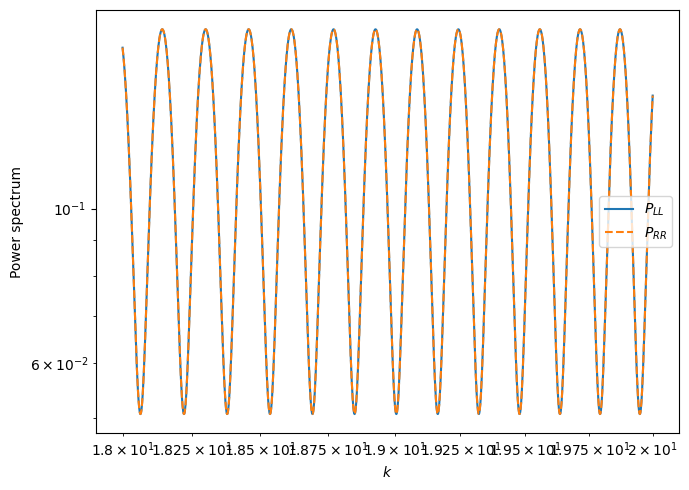


Finished successfully.
minimum normalization margin over sampled (tau,k) = 3.40688786e-03
minimum kinetic margin 1-|c1| over sampled (tau,k) = 9.80000000e-01
max |P_LR - conj(P_RL)| = 0.00000000e+00
max Pi identity error = 2.17978847e-16

Outputs:
  WKB_zoom_18_20/CS/case_33/parity_violation_power_spectra.csv
  WKB_zoom_18_20/CS/case_33/parity_power_spectrum_LL_RR.png
  WKB_zoom_18_20/CS/case_33/parity_asymmetry_Pi.png
  WKB_zoom_18_20/CS/case_33/parity_cross_power_RL.png
  WKB_zoom_18_20/CS/case_33/parity_normalizability_margin.png


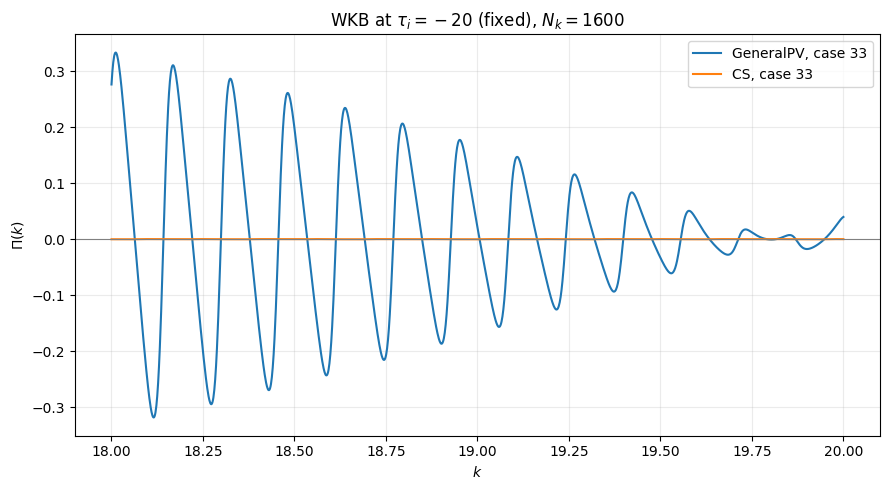

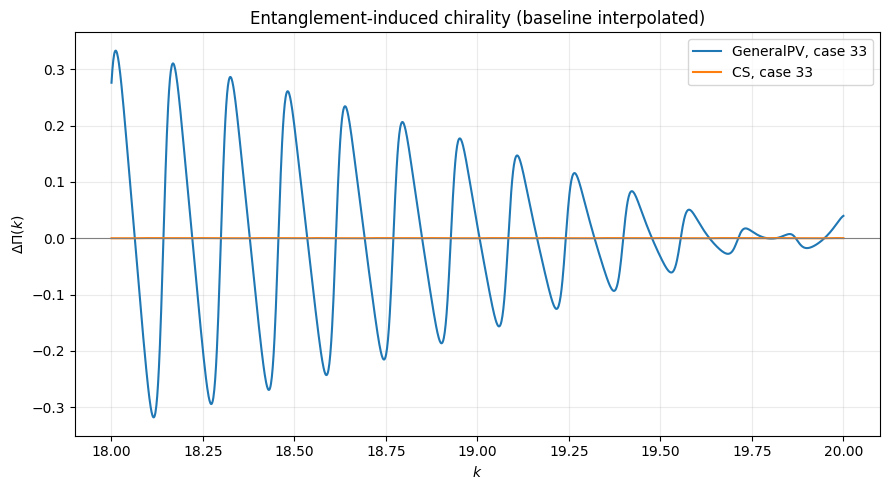

Zoom outputs saved under: /Users/ueda/Desktop/GWsEntanglement/WKB_zoom_18_20


In [ ]:
RUN_ZOOM_K15 = True  # <-- change to True to run this optional zoom
ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K = 18.0, 20.0, 1600
ZOOM_TAUI, ZOOM_TAU0 = -20.0, -1.0
ZOOM_TAUF = -1.0e-3 / 30.0   # identical to the old 1..30 scan
ZOOM_MODELS = [("GeneralPV", 5.0, 1.0), ("CS", 5.0, 5.0)]
ZOOM_CASES = [("33", 0.30, 0.30)]
ZOOM_ROOT = Path("WKB_zoom_18_20")

if RUN_ZOOM_K15:
    if "main" not in globals():
        raise RuntimeError("Execute the model-definition cell before this zoom cell.")

    zoom_saved_config = {name: globals()[name] for name in (
        "K_MIN", "K_MAX", "N_K", "TAUI", "TAU0", "TAUF",
        "ALPHA", "BETA", "BTILDE1_AMP", "BTILDE2_AMP", "INITIAL_MODE", "OUTPUT_DIR"
    )}
    zoom_results = {}
    try:
        K_MIN, K_MAX, N_K = ZOOM_K_MIN, ZOOM_K_MAX, ZOOM_N_K
        TAUI, TAU0, TAUF = ZOOM_TAUI, ZOOM_TAU0, ZOOM_TAUF
        INITIAL_MODE = "wkb_transport"
        for model, alpha, beta in ZOOM_MODELS:
            ALPHA, BETA = alpha, beta
            for case, amp1, amp2 in ZOOM_CASES:
                BTILDE1_AMP, BTILDE2_AMP = amp1, amp2
                OUTPUT_DIR = ZOOM_ROOT / model / f"case_{case}"
                zoom_results[(model, case)] = main()
    finally:
        for name, original in zoom_saved_config.items():
            globals()[name] = original

    ZOOM_ROOT.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    for (model, case), r in zoom_results.items():
        ax.plot(r["k"], r["Pi"], label=f"{model}, case {case}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel=r"$k$", ylabel=r"$\Pi(k)$",
           title=rf"WKB at $\tau_i={ZOOM_TAUI:g}$ (fixed), $N_k={ZOOM_N_K}$")
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(ZOOM_ROOT / "Pi_zoom_comparison.png", dpi=200)
    plt.show()

    # Optional delta-Pi comparison against original unentangled baselines.
    baseline_files = {
        "CS": Path("CS_from_WKB/case_00/parity_violation_power_spectra.csv"),
        "GeneralPV": Path("parity_violation_General_outputs/case_00/parity_violation_power_spectra.csv"),
    }
    fig, ax = plt.subplots(figsize=(9, 5))
    found = False
    for (model, case), r in zoom_results.items():
        baseline_file = baseline_files.get(model)
        if case == "00" or baseline_file is None or not baseline_file.exists():
            continue
        ref = np.genfromtxt(baseline_file, delimiter=",", names=True)
        baseline = np.interp(r["k"], ref["k"], ref["Pi_LL_minus_RR"])
        ax.plot(r["k"], r["Pi"] - baseline, label=f"{model}, case {case}")
        found = True
    if found:
        ax.axhline(0, color="grey", lw=0.8)
        ax.set(xlabel=r"$k$", ylabel=r"$\Delta\Pi(k)$",
               title="Entanglement-induced chirality (baseline interpolated)")
        ax.legend(); ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(ZOOM_ROOT / "DeltaPi_zoom_comparison.png", dpi=200)
        plt.show()
    else:
        plt.close(fig)
        print("DeltaPi overlay omitted: case_00 baseline CSV files not found.")
    print(f"Zoom outputs saved under: {ZOOM_ROOT.resolve()}")